# Criação do Modelo 2 ( corretor )

## PASSO 2) INICIANDO CRIAÇÃO DA BASE DO CORRETOR

### 2.1) Utilização do modelo treinado no experimento do João para a seleção dos Falsos Negativos e Verdadeiros Negativos que serão utilizados no experimento do corretor

In [1]:
from unidecode import unidecode
import re
import unicodedata
import pandas as pd
from joblib import load
import string
from itertools import product
from sklearn.feature_extraction.text import CountVectorizer

In [2]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\kimli\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [3]:
rf_load = load('rf_exp2.joblib')

### 2.1.1) Realizado o carregamento da base com dados resultado da concatenação dos arquivos BOS e DECCC

In [4]:
base_relato = pd.read_csv('base_geralzao_junto.csv')
base_relato

,n_bop,relato
0,00615/2021.100191-1,"A DECLARANTE ACIMA QUALIFICADA, INFORMA QUE E..."
1,00616/2021.100053-9,A RELATORA ACIMA QUALIFICADA COMPARECE NESTA ...
2,00616/2021.100190-3,A RELATORA ACIMA QUALIFICADA COMPARECE NESTA ...
3,00616/2021.100222-0,A RELATORA ACIMA QUALIFICADA COMPARECE NESTA ...
4,00616/2021.100016-0,O RELATOR ACIMA QUALIFICADO COMPARECE NESTA D...
...,...,...
766,00487/2020.100303-9,O RELATOR COMPARECE NESTA DIVISAO DE POLICIA ...
767,00615/2020.100363-4,A VITIMA RELATA QUE NO DIA E HORA SUPRACITADO...
768,00615/2020.100847-3,A CIDADA ACIMA QUALIFICADA COMPARECEU NESTA D...
769,00615/2020.100746-2,A RELATORA COMPARECE NESTA DIVISAO DE POLICIA...


In [5]:
base_para_teste = base_relato.sample(frac=0.3, random_state=42)
base_para_teste

,n_bop,relato
671,00487/2020.100515-6,A VITIMA RELATA QUE NO 15 DE FEVEREIRO DE 202...
286,00613/2020.100011-6,RELATA NESTA DIRETORIA QUE SEU AMIGO DANIEL KO...
728,00616/2020.100235-7,A RELATORA REPRESENTANDO SEU FILHO M.D.C.L AT...
434,00487/2020.100479-0,A RELATORA COMPARECE NESTA DIVISAO DE POLICIA ...
734,00487/2020.100231-0,A RELATORA COMPARECE NESTA DIVISAO PARA REGIS...
...,...,...
706,00615/2020.100029-0,TRATA-SE DE BOLETIM DE OCORRENCIA POLICIAL RE...
622,00615/2020.100651-9,A RELATORA COMPARECE NESTA DIVISAO DE POLICIA...
198,00615/2022.100072-1,O RELATOR ACIMA QUALIFICADO COMPARECEU NESTA ...
631,00616/2020.100002-4,CONFORME MANDADO DE BUSCA PESSOAL DE LAVRA DO...


In [6]:
base_para_teste.to_csv('base_para_teste_final.csv', index=False)

In [7]:
duplicates = base_relato[~base_relato.isin(base_para_teste)]
duplicates

,n_bop,relato
0,00615/2021.100191-1,"A DECLARANTE ACIMA QUALIFICADA, INFORMA QUE E..."
1,00616/2021.100053-9,A RELATORA ACIMA QUALIFICADA COMPARECE NESTA ...
2,NaN,NaN
3,00616/2021.100222-0,A RELATORA ACIMA QUALIFICADA COMPARECE NESTA ...
4,00616/2021.100016-0,O RELATOR ACIMA QUALIFICADO COMPARECE NESTA D...
...,...,...
766,NaN,NaN
767,NaN,NaN
768,00615/2020.100847-3,A CIDADA ACIMA QUALIFICADA COMPARECEU NESTA D...
769,NaN,NaN


In [8]:
base_relato = duplicates.dropna().reset_index(drop=True)
base_relato

,n_bop,relato
0,00615/2021.100191-1,"A DECLARANTE ACIMA QUALIFICADA, INFORMA QUE E..."
1,00616/2021.100053-9,A RELATORA ACIMA QUALIFICADA COMPARECE NESTA ...
2,00616/2021.100222-0,A RELATORA ACIMA QUALIFICADA COMPARECE NESTA ...
3,00616/2021.100016-0,O RELATOR ACIMA QUALIFICADO COMPARECE NESTA D...
4,00615/2021.100752-2,O RELATOR ACIMA QUALIFICADO COMPARECE NESTA D...
...,...,...
535,00615/2020.100234-6,A RELATORA COMPARECEU NESTA DIVISAO PARA REGI...
536,00615/2020.100692-5,"O RELATOR PRESIDENTE DOS AUTOS, REFERENTE A O..."
537,00615/2020.100384-0,O RELATOR ACIMA IDENTIFICADO COMPARECE NESTA ...
538,00615/2020.100847-3,A CIDADA ACIMA QUALIFICADA COMPARECEU NESTA D...


In [9]:
def normalize_text(text):
    if pd.isna(text):
        return text
    text = unicodedata.normalize('NFKD', text)
    text = ''.join(c for c in text if not unicodedata.combining(c))
    return text.upper()

In [10]:
base_relato['relato'] = base_relato['relato'].apply(normalize_text)
base_relato

,n_bop,relato
0,00615/2021.100191-1,"A DECLARANTE ACIMA QUALIFICADA, INFORMA QUE E..."
1,00616/2021.100053-9,A RELATORA ACIMA QUALIFICADA COMPARECE NESTA ...
2,00616/2021.100222-0,A RELATORA ACIMA QUALIFICADA COMPARECE NESTA ...
3,00616/2021.100016-0,O RELATOR ACIMA QUALIFICADO COMPARECE NESTA D...
4,00615/2021.100752-2,O RELATOR ACIMA QUALIFICADO COMPARECE NESTA D...
...,...,...
535,00615/2020.100234-6,A RELATORA COMPARECEU NESTA DIVISAO PARA REGI...
536,00615/2020.100692-5,"O RELATOR PRESIDENTE DOS AUTOS, REFERENTE A O..."
537,00615/2020.100384-0,O RELATOR ACIMA IDENTIFICADO COMPARECE NESTA ...
538,00615/2020.100847-3,A CIDADA ACIMA QUALIFICADA COMPARECEU NESTA D...


### 2.1.3) carregamento do gabarito atualizado

Com a aquisição de novos dados para o experimento o gabarito necessitou de atualização, comportando possiveis tokens novos na base de dados DECCC. Por este motivo, agora há uma diferença entre o gabarito da construção do modelo 1 e o gabarito do modelo dois.


Em tese, não há impacto tão significativo para o experimento do modelo 1. Já que o conteúdo do gabarito sofreu um aumento do volume de dados e não uma redução.

In [11]:
gab = pd.read_csv(r'gabarito_corretor.csv')
gab.shape

(9148, 2)

### 2.1.4) Pré-processamento

Realizando o pré-processamento removendo: Stopwords, caracteres especias, números e pontuação dos relatos.

In [12]:
def preprocess(relato):
    def remove_stop_words(relato):
        # Remove stop words em português
        sw = stopwords.words('portuguese')
        sw = [unidecode(word).upper() for word in sw]
        return ' '.join([token for token in re.split("[, ]", relato) if len(token) > 2 and token not in sw])
    
    def clean_relato(relato):
        # Remoção de números e pontuação
        relato = re.sub(r'(<[^<>]*>)|(&NBSP;)|(&nbsp;)', " ", relato)
        relato = re.sub(r"[^\w\s]", " ", relato)
        relato = re.sub(r"[\d]", " ", relato)
        relato = remove_stop_words(relato)
        return relato
    
    relato = clean_relato(relato)
    return relato

verificação do sucesso do pré-processamento

In [13]:
base_relato['relato_tratado'] = base_relato['relato'].apply(preprocess)
base_relato

,n_bop,relato,relato_tratado
0,00615/2021.100191-1,"A DECLARANTE ACIMA QUALIFICADA, INFORMA QUE E...",DECLARANTE ACIMA QUALIFICADA INFORMA PROFESSOR...
1,00616/2021.100053-9,A RELATORA ACIMA QUALIFICADA COMPARECE NESTA ...,RELATORA ACIMA QUALIFICADA COMPARECE NESTA DIV...
2,00616/2021.100222-0,A RELATORA ACIMA QUALIFICADA COMPARECE NESTA ...,RELATORA ACIMA QUALIFICADA COMPARECE NESTA DIV...
3,00616/2021.100016-0,O RELATOR ACIMA QUALIFICADO COMPARECE NESTA D...,RELATOR ACIMA QUALIFICADO COMPARECE NESTA DIVI...
4,00615/2021.100752-2,O RELATOR ACIMA QUALIFICADO COMPARECE NESTA D...,RELATOR ACIMA QUALIFICADO COMPARECE NESTA DIVI...
...,...,...,...
535,00615/2020.100234-6,A RELATORA COMPARECEU NESTA DIVISAO PARA REGI...,RELATORA COMPARECEU NESTA DIVISAO REGISTRAR EN...
536,00615/2020.100692-5,"O RELATOR PRESIDENTE DOS AUTOS, REFERENTE A O...",RELATOR PRESIDENTE AUTOS REFERENTE OPERACAO WH...
537,00615/2020.100384-0,O RELATOR ACIMA IDENTIFICADO COMPARECE NESTA ...,RELATOR ACIMA IDENTIFICADO COMPARECE NESTA DIV...
538,00615/2020.100847-3,A CIDADA ACIMA QUALIFICADA COMPARECEU NESTA D...,CIDADA ACIMA QUALIFICADA COMPARECEU NESTA DIVI...


### 2.1.5) Identificação dos falsos negativos

Neste trecho é realizada a identificação e criação de um DataFrame com os falsos negativos (tokens classificados como palavra '0', pelo modelo, que na verdade são nomes '1', no gabarito) após a predição dos tokens do relato relato

In [14]:
def false_negative(df_bop: pd.DataFrame):
    fn_list = []

    for n_bop, text in zip(df_bop['n_bop'], df_bop['relato_tratado']):
        text = text.split()
        df = pd.DataFrame(text, columns=['palavra'])
        
        df['y_palavra'] = rf_load.predict(df['palavra'].to_list())

        df['predecessor'] = df['palavra'].shift(1).fillna('#')
        df['y_predecessor'] = df['predecessor'].apply(lambda x: df[df['palavra'] == x]['y_palavra'].iloc[0] if not df[df['palavra'] == x].empty else 2)
        
        df['sucessor'] = df['palavra'].shift(-1).fillna('#')
        df['y_sucessor'] = df['sucessor'].apply(lambda x: df[df['palavra'] == x]['y_palavra'].iloc[0] if not df[df['palavra'] == x].empty else 2)
        
        for _, row in df.iterrows():
            y_true_row = gab[gab['palavra'] == row['palavra']]
            y_true = y_true_row['y'].iloc[0] if not y_true_row.empty else 0
            
            if row['y_palavra'] == 0 and y_true == 1:
                fn_list.append({
                    'predecessor': row['predecessor'],
                    'y_predecessor': int(row['y_predecessor']),
                    'palavra': row['palavra'],
                    'y_palavra': int(row['y_palavra']),
                    'sucessor': row['sucessor'],
                    'y_sucessor': int(row['y_sucessor']),
                    'n_bop': n_bop
                })
                
    return pd.DataFrame(fn_list)


### 2.1.6) Identificação dos verdadeiros negativos

Neste trecho é realizada a identificação e criação de um DataFrame com os verdadeiros negativos (tokens classificados como palavra '0', pelo modelo, e que realmente são palavras '0', no gabarito) após a predição dos tokens do relato

In [15]:
def true_negative(df_bop: pd.DataFrame):
    tn_list = []

    for n_bop, text in zip(df_bop['n_bop'], df_bop['relato_tratado']):
        text = text.split()
        df = pd.DataFrame(text, columns=['palavra'])
        
        df['y_palavra'] = rf_load.predict(df['palavra'].to_list())

        df['predecessor'] = df['palavra'].shift(1).fillna('#')
        df['y_predecessor'] = df['predecessor'].apply(lambda x: df[df['palavra'] == x]['y_palavra'].iloc[0] if not df[df['palavra'] == x].empty else 2)
        
        df['sucessor'] = df['palavra'].shift(-1).fillna('#')
        df['y_sucessor'] = df['sucessor'].apply(lambda x: df[df['palavra'] == x]['y_palavra'].iloc[0] if not df[df['palavra'] == x].empty else 2)
        
        for _, row in df.iterrows():
            y_true_row = gab[gab['palavra'] == row['palavra']]
            y_true = y_true_row['y'].iloc[0] if not y_true_row.empty else 0
            
            if row['y_palavra'] == 0 and y_true == 0:
                tn_list.append({
                    'predecessor': row['predecessor'],
                    'y_predecessor': int(row['y_predecessor']),
                    'palavra': row['palavra'],
                    'y_palavra': int(row['y_palavra']),
                    'sucessor': row['sucessor'],
                    'y_sucessor': int(row['y_sucessor']),
                    'n_bop': n_bop
                })
    return pd.DataFrame(tn_list)


In [16]:
tn_base_relatos = true_negative(base_relato)
fn_base_relatos = false_negative(base_relato)

### 2.1.7) Tratamentos das celulas vazias

Surgiu um desafio na etapa da realização da captura dos predecessores e sucessores. Foram identificados, em alguns casos, a inexistencia de um predecessor ou sucessor do token classificado. Por exemplo, 'RELATOR', que se localiza no início dos textos, é um VERDADEIRO NEGATIVO, e por ser a primeira palavra do vetor de tokens não possui predecessor. Também ocorreram problemas na captura dos FALSOS NEGATIVOS, ouve a ocorrência de dois nomes que se localizavam no fim do vetor de tokens, estas não possuiam sucessores.

Qual o problema? Devido a falta do valor do preditor acerca da palavra inexistente, ele armazena apenas '' (vazio). Isso é um problema já que os modelos utilizados trabalham apenas com dados numéricos.

Estas ocorrências, por mais raras que possa parecer, são desafios que nosso modelo deve estar preparado, visto que há sim grandes chances de ele se deparar com situações como esta em um ambiente real.

Diante disso, foi elaborada uma estratégia para tratar este erro.

Foi implementada uma nova categoria, justamente para solucionar este problema. Assim, palavras que não possuem predecessor ou sucessores, receberão como valor para os respectivos vizinhos o número inteiro '2'.

Logo, temos estas categorias para os tokens de predecessor ou sucessores:

0 - palavra  
1 - nome  
2 - predecessor ou sucessor inexistente  

##### A presença do caracter coringa

A adição do caracter coringa ocorre quando um determinado token não possue um sucessor ou predecessor. Esse evento ocorre quando se dá o início do texto e o fim do mesmo. Podemos identificar pelas ocorrências de palavras que estão sendo inseridas no início dos relatos. Não necessáriamente será realmente a primeira ou a última palavra do texto preprocessado o motivo é simples. O pré-processamento irá remover stopwords, logo não podemos nos basear pelo relato antes do pré-processamento, mas sim pelo relato após as motificações.

In [17]:
fn_base_relatos[fn_base_relatos['y_predecessor'] == 2]

,predecessor,y_predecessor,palavra,y_palavra,sucessor,y_sucessor,n_bop


In [18]:
tn_base_relatos[tn_base_relatos['y_predecessor'] == 2]

,predecessor,y_predecessor,palavra,y_palavra,sucessor,y_sucessor,n_bop
0,#,2,DECLARANTE,0,ACIMA,0,00615/2021.100191-1
96,#,2,RELATORA,0,ACIMA,0,00616/2021.100053-9
202,#,2,RELATORA,0,ACIMA,0,00616/2021.100222-0
242,#,2,RELATOR,0,ACIMA,0,00616/2021.100016-0
328,#,2,RELATOR,0,ACIMA,0,00615/2021.100752-2
...,...,...,...,...,...,...,...
44163,#,2,RELATORA,0,COMPARECEU,0,00615/2020.100234-6
44317,#,2,RELATOR,0,PRESIDENTE,0,00615/2020.100692-5
44346,#,2,RELATOR,0,ACIMA,0,00615/2020.100384-0
44386,#,2,CIDADA,0,ACIMA,0,00615/2020.100847-3


In [19]:
fn_base_relatos[fn_base_relatos['y_sucessor'] == 2]

,predecessor,y_predecessor,palavra,y_palavra,sucessor,y_sucessor,n_bop
44,ZAHLUTH,1,BARBALHO,0,#,2,00614/2022.100007-0


In [20]:
tn_base_relatos[tn_base_relatos['y_sucessor'] == 2]

,predecessor,y_predecessor,palavra,y_palavra,sucessor,y_sucessor,n_bop
95,DEVIDAS,0,PROVIDENCIAS,0,#,2,00615/2021.100191-1
201,PROVIDENCIAS,0,CABIVEIS,0,#,2,00616/2021.100053-9
241,PROVIDENCIAS,0,CABIVEIS,0,#,2,00616/2021.100222-0
327,PROVIDENCIAS,0,CABIVEIS,0,#,2,00616/2021.100016-0
412,PROVIDENCIAS,0,CABIVEIS,0,#,2,00615/2021.100752-2
...,...,...,...,...,...,...,...
44316,LEGAIS,0,CABIVEIS,0,#,2,00615/2020.100234-6
44345,PROVIDENCIAS,0,LEGAIS,0,#,2,00615/2020.100692-5
44385,DEVIDAS,0,PROVIDENCIA,0,#,2,00615/2020.100384-0
44467,FIM,0,RELATO,0,#,2,00615/2020.100847-3


### 2.1.8) Seleção dos VERDADEIROS NEGATIVOS para o balanceamento da base

Aqui é realizada a seleção pseudo-aleatória das amostras da base de VERDADEIROS NEGATIVOS, isso é realizado pelo fato da base de verdadeiros negativos ser muito superior a base de FALSOS NEGATIVOS.  

Logo, para que ambas as bases possuam o mesmo número de amostras, foi realizada a extração 'aleatória' de 406  amostras da base de VERDADEIROS NEGATIVOS. (Faço isso aqui, pra melhorar o desempenho kakakakka)

## PASSO 3) Criação do Vetor de Bigramas dos Falsos Negativos e Verdadeiros Negativos

Este é o mesmo modelo de vetor de bigramas dos experimentos anteriores, podes visualizar logo mais a frente.

In [21]:
def bigrams_vector(lista_fn):
    alfabeto = list(string.ascii_uppercase)
    alfabeto_bigrams = [''.join(bigram) for bigram in list(product(alfabeto, repeat=2))]
    vectorizer = CountVectorizer(analyzer='char', vocabulary=alfabeto_bigrams, lowercase=False, ngram_range=(2, 2))
    vector = vectorizer.fit_transform(lista_fn)
    return pd.DataFrame(vector.todense(), columns=alfabeto_bigrams), vectorizer

In [22]:
palavra = fn_base_relatos['palavra']
fn_vector_bigrams, vectorizer = bigrams_vector(palavra.to_list())
fn_vector_bigrams

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZQ,ZR,ZS,ZT,ZU,ZV,ZW,ZX,ZY,ZZ
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
330,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
331,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
332,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
333,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [23]:
palavra = tn_base_relatos['palavra']
tn_vector_bigrams, vectorizer = bigrams_vector(palavra.to_list())
tn_vector_bigrams

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZQ,ZR,ZS,ZT,ZU,ZV,ZW,ZX,ZY,ZZ
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44509,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
44510,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
44511,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
44512,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## PASSO 4) Concatenação DA PREDIÇÃO DOS FNs e TNs coletados

adiciono também os tokens pra vefificação do que foi predito

In [24]:
fn_vector_bigrams = pd.concat([fn_vector_bigrams, fn_base_relatos[['predecessor', 'y_predecessor', 'palavra','sucessor','y_sucessor']]], axis=1)
fn_vector_bigrams

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZV,ZW,ZX,ZY,ZZ,predecessor,y_predecessor,palavra,sucessor,y_sucessor
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,MARCOS,1,BARRETO,CNPJ,1
1,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,BANCO,0,SAFRA,RELATOR,0
2,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,BANCO,0,SAFRA,APOS,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,PLATAFORMA,0,FARIA,PIX,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,YURI,1,CAMPOS,CPF,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
330,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,KARINA,1,FRAZAO,LOPES,1
331,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,MOTOCICLETA,0,MARCA,YAMAHA,1
332,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,CELULAR,0,MARCA,MODELO,0
333,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,RENAN,1,SANTIAGOSANTOS,SILVA,1


In [25]:
tn_vector_bigrams = pd.concat([tn_vector_bigrams, tn_base_relatos[['predecessor', 'y_predecessor', 'palavra','sucessor','y_sucessor']]], axis=1)
tn_vector_bigrams

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZV,ZW,ZX,ZY,ZZ,predecessor,y_predecessor,palavra,sucessor,y_sucessor
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,#,2,DECLARANTE,ACIMA,0
1,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,DECLARANTE,0,ACIMA,QUALIFICADA,0
2,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,ACIMA,0,QUALIFICADA,INFORMA,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,QUALIFICADA,0,INFORMA,PROFESSORA,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,INFORMA,0,PROFESSORA,LINGUA,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44509,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,FILHA,1,PEDIR,QUANTIAS,0
44510,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,PEDIR,0,QUANTIAS,DINHEIRO,1
44511,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,DINHEIRO,1,REGISTRA,DEVIDOS,0
44512,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,REGISTRA,0,DEVIDOS,FINS,0


## Passo 5) Realização da Classificação Gramatical dos Falsos Negativos e Verdadeiros Positivos

In [26]:
import spacy as scy
from sklearn.preprocessing import LabelEncoder

In [27]:
nlp = scy.load('pt_core_news_lg')

In [28]:
lb = LabelEncoder()

### 5.1) Criação dos labels da classificação gramatical

No código que aproveitei do classificador do spacy, possuia a renomeação dos labels para 'pt-br', digamos assim. Por essa questão, não alterei já que a visualização se torna bem melhor para validação dos resultados exibidos pelo classificador, então foram criadas 14 labels para a classificação, estes estão listado abaixo:

In [29]:
labels = ['<SUBSTANTIVO>', '<VERBO>', '<ADJETIVO>', '<ADVERBIO>', '<PONTUACAO>',
            '<CONJUNCAO>', '<PRONOME>', '<ARTIGO>', '<PREPOSIÇÃO>', '<NUMERAL>',
            '<SIMBOLO>', '<PALAVRA ESTRANGEIRA>', '<ESPACO>', '<NULL>']

In [30]:
lb.fit(labels)

LabelEncoder()

In [31]:
lb.classes_

array(['<ADJETIVO>', '<ADVERBIO>', '<ARTIGO>', '<CONJUNCAO>', '<ESPACO>',
       '<NULL>', '<NUMERAL>', '<PALAVRA ESTRANGEIRA>', '<PONTUACAO>',
       '<PREPOSIÇÃO>', '<PRONOME>', '<SIMBOLO>', '<SUBSTANTIVO>',
       '<VERBO>'], dtype='<U21')

adicionar a modificação pra deixar esse código melhor o map que foi feito na etapa de testes do experimento do corretor

In [32]:
def renomear(doc):

    csf = []
    for token in doc:
        if token.pos_ == 'NOUN' or token.pos_ == 'PROPN':
            csf.append('<SUBSTANTIVO>')
        elif token.pos_ == 'VERB' or token.pos_ == 'AUX':
            csf.append('<VERBO>')
        elif token.pos_ == 'ADJ':
            csf.append('<ADJETIVO>')
        elif token.pos_ == 'ADV':
            csf.append('<ADVERBIO>')
        elif token.pos_ == 'PUNCT':
            csf.append('<PONTUACAO>')
        elif token.pos_ == 'CCONJ' or token.pos_ == 'SCONJ':
            csf.append('<CONJUNCAO>')
        elif token.pos_ == 'PRON':
            csf.append('<PRONOME>')
        elif token.pos_ == 'DET':
            csf.append('<ARTIGO>')
        elif token.pos_ == 'ADP':
            csf.append('<PREPOSIÇÃO>')
        elif token.pos_ == 'NUM':
            csf.append('<NUMERAL>')
        elif token.pos_ == 'SYM':
            csf.append('<SIMBOLO>')
        elif token.pos_ == 'X':
            csf.append('<PALAVRA ESTRANGEIRA>')
        elif token.pos_ == 'SPACE':
            csf.append('<ESPACO>')
    return csf


### 5.2) Tratamento dos valores vazios de predecessores e sucessores

Sim, teve dor de cabeça para os predecessores e sucessores inexistentes aqui também. Este foi solucionado de maneira mais simples.

Se observar na lista anterior de labels, podes identificar um label que não é encontrado na função de renomear, aqui em cima. Esse carinha é o <NULL>

Esse cara será a nossa classificação gramatical para os nulos, já que não tem como classificar os mesmos com nada além disso, já que eles não existem.

Logo, aqui a baixo podes ler:

Se token == '#':
    adicione na lista word_class <NULL>

tratando os nossos predecessores e sucessores vazios

In [33]:
def create_base_cg(lista_tokens):
    word_class = []
    for token in lista_tokens:
        if token == '#':
            word_class.append('<NULL>')
        else:
            lreview = token.lower()
            ldoc = nlp(lreview)
            classes = renomear(ldoc)
            for i in range(len(token.split())):
                word_class.append(classes[i])

    return pd.DataFrame({'palavra':lista_tokens, 'classe':word_class})

Aqui é onde realizo a chamada da função que irá realizar a classificação de todo mundo, tanto da palavra, quanto do predecessor e sucessor. Adicionando a mesma juntamente com o vetor de bigramas e a predição do predecessor e sucessor.

In [34]:
fn_vector_bigrams['cg_p'] = create_base_cg(fn_base_relatos['predecessor'])['classe']
fn_vector_bigrams['cg_w'] = create_base_cg(fn_base_relatos['palavra'])['classe']
fn_vector_bigrams['cg_s'] = create_base_cg(fn_base_relatos['sucessor'])['classe']

In [35]:
fn_vector_bigrams['cg_p'] = lb.transform(fn_vector_bigrams['cg_p'])
fn_vector_bigrams['cg_w'] = lb.transform(fn_vector_bigrams['cg_w'])
fn_vector_bigrams['cg_s'] = lb.transform(fn_vector_bigrams['cg_s'])
fn_vector_bigrams

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZY,ZZ,predecessor,y_predecessor,palavra,sucessor,y_sucessor,cg_p,cg_w,cg_s
0,0,0,0,0,0,0,0,0,0,0,...,0,0,MARCOS,1,BARRETO,CNPJ,1,12,12,13
1,0,0,0,0,0,1,0,0,0,0,...,0,0,BANCO,0,SAFRA,RELATOR,0,12,12,12
2,0,0,0,0,0,1,0,0,0,0,...,0,0,BANCO,0,SAFRA,APOS,0,12,12,12
3,0,0,0,0,0,0,0,0,0,0,...,0,0,PLATAFORMA,0,FARIA,PIX,0,12,13,12
4,0,0,0,0,0,0,0,0,0,0,...,0,0,YURI,1,CAMPOS,CPF,1,12,12,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
330,0,0,0,0,0,0,0,0,0,0,...,0,0,KARINA,1,FRAZAO,LOPES,1,12,0,12
331,0,0,0,0,0,0,0,0,0,0,...,0,0,MOTOCICLETA,0,MARCA,YAMAHA,1,12,12,12
332,0,0,0,0,0,0,0,0,0,0,...,0,0,CELULAR,0,MARCA,MODELO,0,12,12,12
333,0,0,0,0,0,0,1,0,0,0,...,0,0,RENAN,1,SANTIAGOSANTOS,SILVA,1,12,13,12


In [36]:
tn_vector_bigrams['cg_p'] = create_base_cg(tn_base_relatos['predecessor'])['classe']
tn_vector_bigrams['cg_w'] = create_base_cg(tn_base_relatos['palavra'])['classe']
tn_vector_bigrams['cg_s'] = create_base_cg(tn_base_relatos['sucessor'])['classe']

In [37]:
tn_vector_bigrams['cg_p'] = lb.transform(tn_vector_bigrams['cg_p'])
tn_vector_bigrams['cg_w'] = lb.transform(tn_vector_bigrams['cg_w'])
tn_vector_bigrams['cg_s'] = lb.transform(tn_vector_bigrams['cg_s'])
tn_vector_bigrams

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZY,ZZ,predecessor,y_predecessor,palavra,sucessor,y_sucessor,cg_p,cg_w,cg_s
0,0,0,0,0,0,0,0,0,0,0,...,0,0,#,2,DECLARANTE,ACIMA,0,5,0,1
1,0,0,1,0,0,0,0,0,0,0,...,0,0,DECLARANTE,0,ACIMA,QUALIFICADA,0,0,1,0
2,0,0,0,1,0,0,0,0,0,0,...,0,0,ACIMA,0,QUALIFICADA,INFORMA,0,1,0,13
3,0,0,0,0,0,0,0,0,0,0,...,0,0,QUALIFICADA,0,INFORMA,PROFESSORA,0,0,13,12
4,0,0,0,0,0,0,0,0,0,0,...,0,0,INFORMA,0,PROFESSORA,LINGUA,1,13,12,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44509,0,0,0,0,0,0,0,0,0,0,...,0,0,FILHA,1,PEDIR,QUANTIAS,0,12,13,12
44510,0,0,0,0,0,0,0,0,0,0,...,0,0,PEDIR,0,QUANTIAS,DINHEIRO,1,13,12,12
44511,0,0,0,0,0,0,0,0,0,0,...,0,0,DINHEIRO,1,REGISTRA,DEVIDOS,0,12,13,13
44512,0,0,0,0,0,0,0,0,0,0,...,0,0,REGISTRA,0,DEVIDOS,FINS,0,13,13,12


In [38]:
for index, classe in zip(range(0, len(lb.classes_)), lb.classes_):
    print(str(index) + ' ' + classe)

0 <ADJETIVO>
1 <ADVERBIO>
2 <ARTIGO>
3 <CONJUNCAO>
4 <ESPACO>
5 <NULL>
6 <NUMERAL>
7 <PALAVRA ESTRANGEIRA>
8 <PONTUACAO>
9 <PREPOSIÇÃO>
10 <PRONOME>
11 <SIMBOLO>
12 <SUBSTANTIVO>
13 <VERBO>


### 5.3) Drop duplicates

remoção dos dados duplicados

In [39]:
fn_vector_bigrams.shape

(335, 684)

In [40]:
fn_vector_bigrams = fn_vector_bigrams.drop_duplicates()
fn_vector_bigrams.shape

(276, 684)

In [41]:
fn_base_final = fn_vector_bigrams.drop(['sucessor', 'predecessor','palavra'], axis=1)
fn_base_final

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZV,ZW,ZX,ZY,ZZ,y_predecessor,y_sucessor,cg_p,cg_w,cg_s
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,12,13
1,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,12,12,12
2,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,12,12,12
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,12,13,12
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,12,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
329,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,12,12
330,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,0,12
331,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,12,12,12
333,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,1,1,12,13,12


In [42]:
tn_vector_bigrams = tn_vector_bigrams.drop_duplicates()
tn_vector_bigrams.shape

(34025, 684)

In [43]:
tn_base_final = tn_vector_bigrams.drop(['sucessor', 'predecessor','palavra'], axis=1)
tn_base_final

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZV,ZW,ZX,ZY,ZZ,y_predecessor,y_sucessor,cg_p,cg_w,cg_s
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,2,0,5,0,1
1,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
2,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,13
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,13,12
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,13,12,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44507,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,3,13,0
44508,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,13,0,12
44509,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,12,13,12
44510,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,13,12,12


### 5.4) Armazenamento das bases prontas para treino dos Falsos Negativos e Verdadeiros Negativos

In [44]:
fn_base_final.to_csv('base_fn_cg.csv', index=False)
tn_base_final.to_csv('base_tn_cg.csv', index=False)

no fim temos estes dois arquivos

duas tabelas contendo

Parte 1: Vetor de bigramas do token (O FALSO NEGATIVO OU VERDADEIRO NEGATIVO)  
Parte 2: A resultado da predição do nosso modelo para com os predecessores e sucessores do token representado no vetor de bigramas  
Parte 3: A classificação gramatical do predecessor, da token em si e do sucessor deste token.  

In [45]:
base = pd.read_csv(r"base_fn_cg.csv")
base

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZV,ZW,ZX,ZY,ZZ,y_predecessor,y_sucessor,cg_p,cg_w,cg_s
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,12,13
1,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,12,12,12
2,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,12,12,12
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,12,13,12
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,12,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
271,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,12,12
272,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,0,12
273,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,12,12,12
274,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,1,1,12,13,12


In [46]:
base = pd.read_csv(r"base_tn_cg.csv")
base

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZV,ZW,ZX,ZY,ZZ,y_predecessor,y_sucessor,cg_p,cg_w,cg_s
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,2,0,5,0,1
1,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
2,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,13
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,13,12
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,13,12,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34020,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,3,13,0
34021,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,13,0,12
34022,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,12,13,12
34023,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,13,12,12


## PASSO 6) Realização dos testes na base nova

In [47]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score,  recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

Realizando o carregamento das bases de falsos negativos e verdadeiros negativos criada no arquivo 'criacao_base_fn.ipynb'

In [48]:
fn_base = pd.read_csv(r'base_fn_cg.csv')
tn_base = pd.read_csv(r'base_tn_cg.csv')

setando para os valores de y para o modelo

fn_base que são nossos NOMES que foram classificados como PALAVRAS recebem o rótulo '1'  
tn_base que são nossas PALAVRAS que foram classificados corretamente como PALAVRAS recebem o rótulo '0'

In [49]:
fn_base['y_true'] = 1
tn_base['y_true'] = 0

In [50]:
len(tn_base) / len(fn_base)

123.27898550724638

In [51]:
df2 = tn_base.copy()

In [52]:
count = 0
scores_kfolds = {'acuracia' : [], 'recall': [], 'f1_score':[], 'precisao':[]}

### Tests K-FOLDs ( Random Forest ) 

In [53]:
while(len(df2) >= len(fn_base)):
    buffer_df_tn = df2.sample(n=len(fn_base), random_state=42)
    
    # contat
    base_final = pd.concat([fn_base, buffer_df_tn])

    # resetando o index da base final
    base_final = base_final.reset_index(drop=True)
    
    # labels
    y = base_final['y_true']
    X = base_final.drop(['y_true'], axis=1)

    ## 6.1) Realização da divisão da base para treino e teste - (30% para treino 70% para teste)
    """
    aqui é realizada a divisão da base para treino e teste

    estabelecendo o critério de divisão 30-70

    30% da base sendo utilizada para teste  
    70% da base sendo utilizada para treinamento 

    """

    # separação treino e teste
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

    def tabela_divisao(y_train, y_test):
        treino = pd.DataFrame(y_train.value_counts()).rename({'count': 'Treinamento'}, axis=1).rename_axis(None, axis=0)
        teste = pd.DataFrame(y_test.value_counts()).rename({'count': 'Teste'}, axis=1).rename_axis(None, axis=0)
        df_dist = pd.concat([treino, teste], axis=1)
        df_dist['Total'] = df_dist.sum(axis=1)
        pd.concat([df_dist, df_dist.sum().to_frame('Total').T]).T
        return df_dist.T
    
    tabela_divisao(y_train, y_test)

    y_predictions = {}

    # selecionando Random Forest para treino e teste
    rf = RandomForestClassifier()
    rf.fit(X_train, y_train)

    y_predictions['Random Forest'] = rf.predict(X_test)
    scores_kfolds['acuracia'].append(accuracy_score(y_test, y_predictions['Random Forest']))
    scores_kfolds['recall'].append(recall_score(y_test, y_predictions['Random Forest']))
    scores_kfolds['f1_score'].append(f1_score(y_test, y_predictions['Random Forest']))
    scores_kfolds['precisao'].append(precision_score(y_test, y_predictions['Random Forest']))
    
    # dropando para reiniciar o ciclo
    df2 = df2.drop(buffer_df_tn.index)
    count+=1
    print("Count: " + str(count) + " len df: " + str(df2.shape))

Count: 1 len df: (33749, 682)
Count: 2 len df: (33473, 682)
Count: 3 len df: (33197, 682)
Count: 4 len df: (32921, 682)
Count: 5 len df: (32645, 682)
Count: 6 len df: (32369, 682)
Count: 7 len df: (32093, 682)
Count: 8 len df: (31817, 682)
Count: 9 len df: (31541, 682)
Count: 10 len df: (31265, 682)
Count: 11 len df: (30989, 682)
Count: 12 len df: (30713, 682)
Count: 13 len df: (30437, 682)
Count: 14 len df: (30161, 682)
Count: 15 len df: (29885, 682)
Count: 16 len df: (29609, 682)
Count: 17 len df: (29333, 682)
Count: 18 len df: (29057, 682)
Count: 19 len df: (28781, 682)
Count: 20 len df: (28505, 682)
Count: 21 len df: (28229, 682)
Count: 22 len df: (27953, 682)
Count: 23 len df: (27677, 682)
Count: 24 len df: (27401, 682)
Count: 25 len df: (27125, 682)
Count: 26 len df: (26849, 682)
Count: 27 len df: (26573, 682)
Count: 28 len df: (26297, 682)
Count: 29 len df: (26021, 682)
Count: 30 len df: (25745, 682)
Count: 31 len df: (25469, 682)
Count: 32 len df: (25193, 682)
Count: 33 len df:

In [54]:
import numpy as  np
# média dos resultados
metrica = 0
for metrica in scores_kfolds.keys(): 
    print(metrica + ": " + str(np.mean(scores_kfolds[metrica])))

acuracia: 0.9123812322460574
recall: 0.8977372906259183
f1_score: 0.9112381203450192
precisao: 0.9257086615252059


In [55]:
# desvio padrao dos resultados
idx_metrica = 0
for idx_metrica in scores_kfolds.keys(): 
    print(idx_metrica + ": " + str(np.std(scores_kfolds[idx_metrica])))

acuracia: 0.01615434199422464
recall: 0.013513225084518007
f1_score: 0.01537316413068071
precisao: 0.028409122940231415


Detalhe

C:\Users\kimli\AppData\Local\Temp\ipykernel_1716\542578405.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)


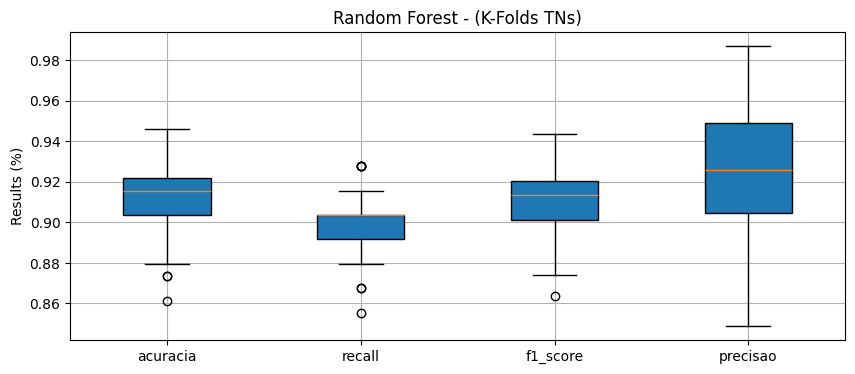

In [56]:
plt.figure(figsize=(10, 4))
plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)
plt.grid(True)
plt.title('Random Forest - (K-Folds TNs)')
plt.ylabel('Results (%)')
# plt.savefig('images/boxplot.png', bbox_inches='tight', dpi = 300)
plt.show()

Geral

C:\Users\kimli\AppData\Local\Temp\ipykernel_1716\3479242761.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)


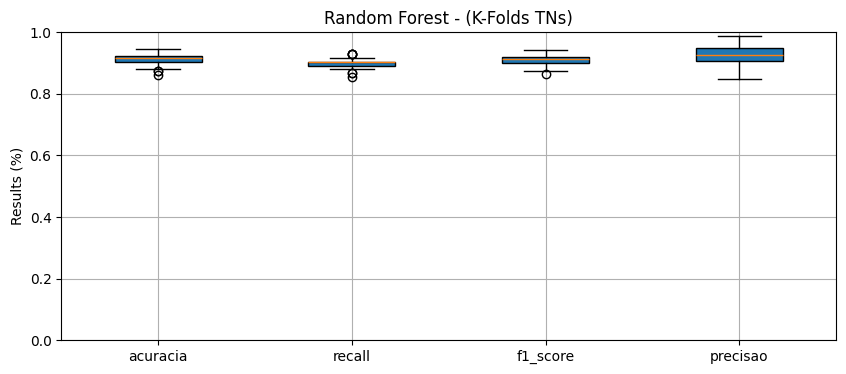

In [57]:
plt.figure(figsize=(10, 4))
plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)
plt.grid(True)
plt.ylim(0.0, 1.0)
plt.title('Random Forest - (K-Folds TNs)')
plt.ylabel('Results (%)')
# plt.savefig('images/boxplot.png', bbox_inches='tight', dpi = 300)
plt.show()

### Tests K-FOLDs ( Support Vector Machine )

In [58]:
df2 = tn_base.copy()
count = 0
scores_kfolds = {'acuracia' : [], 'recall': [], 'f1_score':[], 'precisao':[]}

In [59]:
while(len(df2) >= len(fn_base)):
    buffer_df_tn = df2.sample(n=len(fn_base), random_state=42)
    
    # contat
    base_final = pd.concat([fn_base, buffer_df_tn])

    # resetando o index da base final
    base_final = base_final.reset_index(drop=True)
    
    # labels
    y = base_final['y_true']
    X = base_final.drop(['y_true'], axis=1)

    ## 6.1) Realização da divisão da base para treino e teste - (30% para treino 70% para teste)
    """
    aqui é realizada a divisão da base para treino e teste

    estabelecendo o critério de divisão 30-70

    30% da base sendo utilizada para teste  
    70% da base sendo utilizada para treinamento 

    """

    # separação treino e teste
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

    def tabela_divisao(y_train, y_test):
        treino = pd.DataFrame(y_train.value_counts()).rename({'count': 'Treinamento'}, axis=1).rename_axis(None, axis=0)
        teste = pd.DataFrame(y_test.value_counts()).rename({'count': 'Teste'}, axis=1).rename_axis(None, axis=0)
        df_dist = pd.concat([treino, teste], axis=1)
        df_dist['Total'] = df_dist.sum(axis=1)
        pd.concat([df_dist, df_dist.sum().to_frame('Total').T]).T
        return df_dist.T
    
    tabela_divisao(y_train, y_test)

    y_predictions = {}

    # selecionando Support Vector Machine para treino e teste
    from sklearn.svm import SVC

    clf = SVC(gamma='auto', random_state=42)
    clf.fit(X_train, y_train)

    y_predictions['SVM'] = clf.predict(X_test)
    scores_kfolds['acuracia'].append(accuracy_score(y_test, y_predictions['SVM']))
    scores_kfolds['recall'].append(recall_score(y_test, y_predictions['SVM']))
    scores_kfolds['f1_score'].append(f1_score(y_test, y_predictions['SVM']))
    scores_kfolds['precisao'].append(precision_score(y_test, y_predictions['SVM']))
    
    # dropando para reiniciar o ciclo
    df2 = df2.drop(buffer_df_tn.index)
    count+=1
    print("Count: " + str(count) + " len df: " + str(df2.shape))

Count: 1 len df: (33749, 682)
Count: 2 len df: (33473, 682)
Count: 3 len df: (33197, 682)
Count: 4 len df: (32921, 682)
Count: 5 len df: (32645, 682)
Count: 6 len df: (32369, 682)
Count: 7 len df: (32093, 682)
Count: 8 len df: (31817, 682)
Count: 9 len df: (31541, 682)
Count: 10 len df: (31265, 682)
Count: 11 len df: (30989, 682)
Count: 12 len df: (30713, 682)
Count: 13 len df: (30437, 682)
Count: 14 len df: (30161, 682)
Count: 15 len df: (29885, 682)
Count: 16 len df: (29609, 682)
Count: 17 len df: (29333, 682)
Count: 18 len df: (29057, 682)
Count: 19 len df: (28781, 682)
Count: 20 len df: (28505, 682)
Count: 21 len df: (28229, 682)
Count: 22 len df: (27953, 682)
Count: 23 len df: (27677, 682)
Count: 24 len df: (27401, 682)
Count: 25 len df: (27125, 682)
Count: 26 len df: (26849, 682)
Count: 27 len df: (26573, 682)
Count: 28 len df: (26297, 682)
Count: 29 len df: (26021, 682)
Count: 30 len df: (25745, 682)
Count: 31 len df: (25469, 682)
Count: 32 len df: (25193, 682)
Count: 33 len df:

In [60]:
import numpy as  np
# média dos resultados
metrica = 0
for metrica in scores_kfolds.keys(): 
    print(metrica + ": " + str(np.mean(scores_kfolds[metrica])))

acuracia: 0.5555392300910961
recall: 0.802527181898325
f1_score: 0.643156618074388
precisao: 0.5377021420269441


In [61]:
# desvio padrao dos resultados
idx_metrica = 0
for idx_metrica in scores_kfolds.keys(): 
    print(idx_metrica + ": " + str(np.std(scores_kfolds[idx_metrica])))

acuracia: 0.032075237920310536
recall: 0.056711872062821196
f1_score: 0.02682901816123054
precisao: 0.02242692932815


Detalhes

C:\Users\kimli\AppData\Local\Temp\ipykernel_1716\2022981463.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)


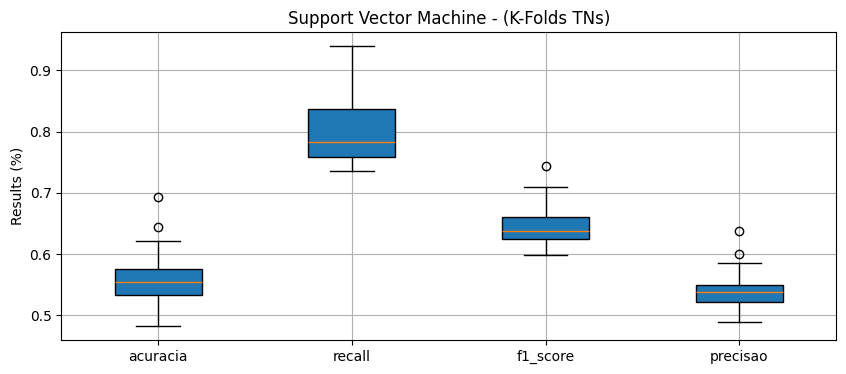

In [62]:
plt.figure(figsize=(10, 4))
plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)
plt.grid(True)
plt.title('Support Vector Machine - (K-Folds TNs)')
plt.ylabel('Results (%)')
# plt.savefig('images/boxplot.png', bbox_inches='tight', dpi = 300)
plt.show()

Geral

C:\Users\kimli\AppData\Local\Temp\ipykernel_1716\16612834.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)


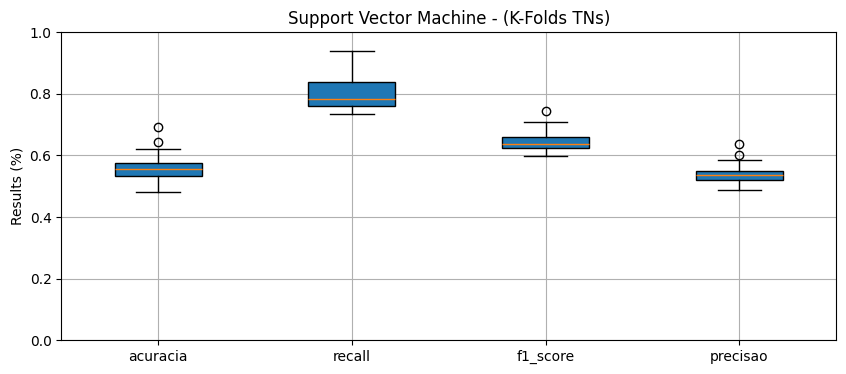

In [63]:
plt.figure(figsize=(10, 4))
plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)
plt.grid(True)
plt.ylim(0.0, 1.0)
plt.title('Support Vector Machine - (K-Folds TNs)')
plt.ylabel('Results (%)')
# plt.savefig('images/boxplot.png', bbox_inches='tight', dpi = 300)
plt.show()

### Logistic Regression ( K-Folds TNs )

In [64]:
df2 = tn_base.copy()
count = 0
scores_kfolds = {'acuracia' : [], 'recall': [], 'f1_score':[], 'precisao':[]}

In [ ]:
while(len(df2) >= len(fn_base)):
    buffer_df_tn = df2.sample(n=len(fn_base), random_state=42)
    
    # contat
    base_final = pd.concat([fn_base, buffer_df_tn])

    # resetando o index da base final
    base_final = base_final.reset_index(drop=True)
    
    # labels
    y = base_final['y_true']
    X = base_final.drop(['y_true'], axis=1)

    ## 6.1) Realização da divisão da base para treino e teste - (30% para treino 70% para teste)
    """
    aqui é realizada a divisão da base para treino e teste

    estabelecendo o critério de divisão 30-70

    30% da base sendo utilizada para teste  
    70% da base sendo utilizada para treinamento 

    """

    # separação treino e teste
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

    def tabela_divisao(y_train, y_test):
        treino = pd.DataFrame(y_train.value_counts()).rename({'count': 'Treinamento'}, axis=1).rename_axis(None, axis=0)
        teste = pd.DataFrame(y_test.value_counts()).rename({'count': 'Teste'}, axis=1).rename_axis(None, axis=0)
        df_dist = pd.concat([treino, teste], axis=1)
        df_dist['Total'] = df_dist.sum(axis=1)
        pd.concat([df_dist, df_dist.sum().to_frame('Total').T]).T
        return df_dist.T
    
    tabela_divisao(y_train, y_test)

    y_predictions = {}

    # selecionando Logistc Regression para treino e teste
    from sklearn.linear_model import LogisticRegression

    model = LogisticRegression(random_state=42)
    model.fit(X_train, y_train)

    y_predictions['Logistc Regression'] = model.predict(X_test)
    scores_kfolds['acuracia'].append(accuracy_score(y_test, y_predictions['Logistc Regression']))
    scores_kfolds['recall'].append(recall_score(y_test, y_predictions['Logistc Regression']))
    scores_kfolds['f1_score'].append(f1_score(y_test, y_predictions['Logistc Regression']))
    scores_kfolds['precisao'].append(precision_score(y_test, y_predictions['Logistc Regression']))
    
    # dropando para reiniciar o ciclo
    df2 = df2.drop(buffer_df_tn.index)
    count+=1
    print("Count: " + str(count) + " len df: " + str(df2.shape))

In [66]:
import numpy as  np
# média dos resultados
metrica = 0
for metrica in scores_kfolds.keys(): 
    print(metrica + ": " + str(np.mean(scores_kfolds[metrica])))

acuracia: 0.8873542952296992
recall: 0.8852972867078069
f1_score: 0.887417306895499
precisao: 0.8903218376339952


In [67]:
# desvio padrao dos resultados
idx_metrica = 0
for idx_metrica in scores_kfolds.keys(): 
    print(idx_metrica + ": " + str(np.std(scores_kfolds[idx_metrica])))

acuracia: 0.02146652697541154
recall: 0.014440646192326264
f1_score: 0.01968286713703608
precisao: 0.03530385118051869


Detalhes

C:\Users\kimli\AppData\Local\Temp\ipykernel_1716\3808316310.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)


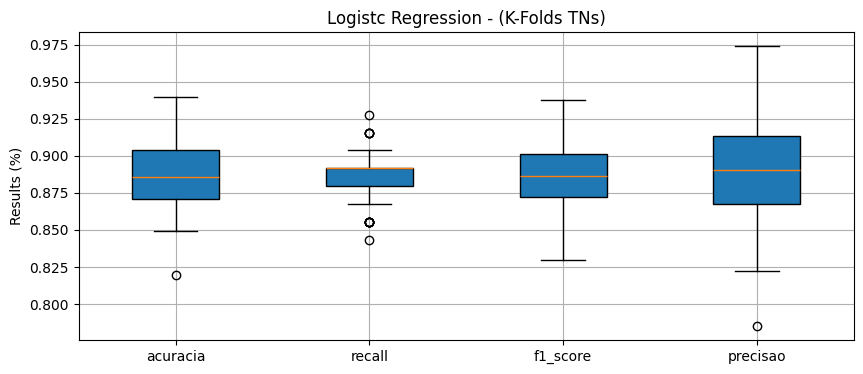

In [68]:
plt.figure(figsize=(10, 4))
plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)
plt.grid(True)
plt.title('Logistc Regression - (K-Folds TNs)')
plt.ylabel('Results (%)')
# plt.savefig('images/boxplot.png', bbox_inches='tight', dpi = 300)
plt.show()

Geral

C:\Users\kimli\AppData\Local\Temp\ipykernel_1716\978512746.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)


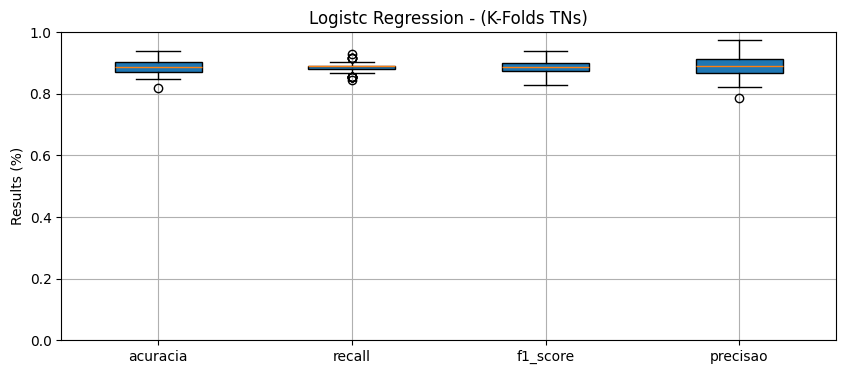

In [69]:
plt.figure(figsize=(10, 4))
plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)
plt.grid(True)
plt.ylim(0.0, 1.0)
plt.title('Logistc Regression - (K-Folds TNs)')
plt.ylabel('Results (%)')
# plt.savefig('images/boxplot.png', bbox_inches='tight', dpi = 300)
plt.show()

### Gradient Boosting ( K-Folds TNs )

In [70]:
df2 = tn_base.copy()
count = 0
scores_kfolds = {'acuracia' : [], 'recall': [], 'f1_score':[], 'precisao':[]}

In [71]:
while(len(df2) >= len(fn_base)):
    buffer_df_tn = df2.sample(n=len(fn_base), random_state=42)
    
    # contat
    base_final = pd.concat([fn_base, buffer_df_tn])

    # resetando o index da base final
    base_final = base_final.reset_index(drop=True)
    
    # labels
    y = base_final['y_true']
    X = base_final.drop(['y_true'], axis=1)

    ## 6.1) Realização da divisão da base para treino e teste - (30% para treino 70% para teste)
    """
    aqui é realizada a divisão da base para treino e teste

    estabelecendo o critério de divisão 30-70

    30% da base sendo utilizada para teste  
    70% da base sendo utilizada para treinamento 

    """

    # separação treino e teste
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

    def tabela_divisao(y_train, y_test):
        treino = pd.DataFrame(y_train.value_counts()).rename({'count': 'Treinamento'}, axis=1).rename_axis(None, axis=0)
        teste = pd.DataFrame(y_test.value_counts()).rename({'count': 'Teste'}, axis=1).rename_axis(None, axis=0)
        df_dist = pd.concat([treino, teste], axis=1)
        df_dist['Total'] = df_dist.sum(axis=1)
        pd.concat([df_dist, df_dist.sum().to_frame('Total').T]).T
        return df_dist.T
    
    tabela_divisao(y_train, y_test)

    y_predictions = {}

    # selecionando Gradient Boosting para treino e teste
    from sklearn.ensemble import GradientBoostingClassifier
    gb = GradientBoostingClassifier(random_state=42)
    gb.fit(X_train, y_train)

    y_predictions['Gradient Boosting'] = gb.predict(X_test)
    scores_kfolds['acuracia'].append(accuracy_score(y_test, y_predictions['Gradient Boosting']))
    scores_kfolds['recall'].append(recall_score(y_test, y_predictions['Gradient Boosting']))
    scores_kfolds['f1_score'].append(f1_score(y_test, y_predictions['Gradient Boosting']))
    scores_kfolds['precisao'].append(precision_score(y_test, y_predictions['Gradient Boosting']))
    
    # dropando para reiniciar o ciclo
    df2 = df2.drop(buffer_df_tn.index)
    count+=1
    print("Count: " + str(count) + " len df: " + str(df2.shape))

Count: 1 len df: (33749, 682)
Count: 2 len df: (33473, 682)
Count: 3 len df: (33197, 682)
Count: 4 len df: (32921, 682)
Count: 5 len df: (32645, 682)
Count: 6 len df: (32369, 682)
Count: 7 len df: (32093, 682)
Count: 8 len df: (31817, 682)
Count: 9 len df: (31541, 682)
Count: 10 len df: (31265, 682)
Count: 11 len df: (30989, 682)
Count: 12 len df: (30713, 682)
Count: 13 len df: (30437, 682)
Count: 14 len df: (30161, 682)
Count: 15 len df: (29885, 682)
Count: 16 len df: (29609, 682)
Count: 17 len df: (29333, 682)
Count: 18 len df: (29057, 682)
Count: 19 len df: (28781, 682)
Count: 20 len df: (28505, 682)
Count: 21 len df: (28229, 682)
Count: 22 len df: (27953, 682)
Count: 23 len df: (27677, 682)
Count: 24 len df: (27401, 682)
Count: 25 len df: (27125, 682)
Count: 26 len df: (26849, 682)
Count: 27 len df: (26573, 682)
Count: 28 len df: (26297, 682)
Count: 29 len df: (26021, 682)
Count: 30 len df: (25745, 682)
Count: 31 len df: (25469, 682)
Count: 32 len df: (25193, 682)
Count: 33 len df:

In [72]:
import numpy as  np
# média dos resultados
metrica = 0
for metrica in scores_kfolds.keys(): 
    print(metrica + ": " + str(np.mean(scores_kfolds[metrica])))

acuracia: 0.8900969732588891
recall: 0.8905867371926733
f1_score: 0.8903993127925529
precisao: 0.8909955284346379


In [73]:
# desvio padrao dos resultados
idx_metrica = 0
for idx_metrica in scores_kfolds.keys(): 
    print(idx_metrica + ": " + str(np.std(scores_kfolds[idx_metrica])))

acuracia: 0.020943464899772543
recall: 0.016871212375695867
f1_score: 0.019353567640674387
precisao: 0.034005525844782274


Detalhes

C:\Users\kimli\AppData\Local\Temp\ipykernel_1716\126384097.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)


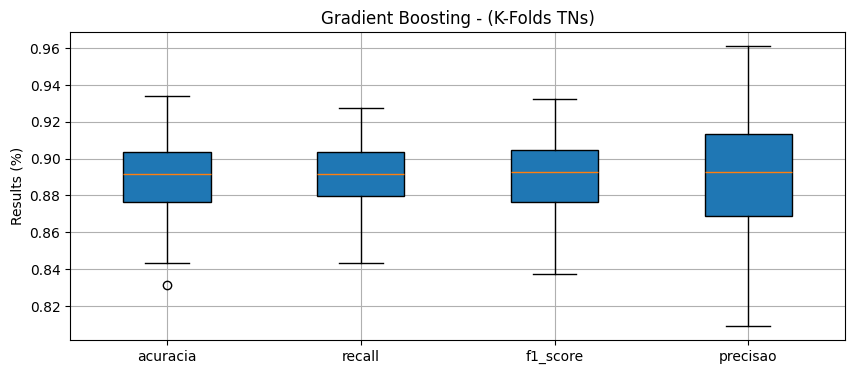

In [74]:
plt.figure(figsize=(10, 4))
plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)
plt.grid(True)
plt.title('Gradient Boosting - (K-Folds TNs)')
plt.ylabel('Results (%)')
# plt.savefig('images/boxplot.png', bbox_inches='tight', dpi = 300)
plt.show()

Geral

C:\Users\kimli\AppData\Local\Temp\ipykernel_1716\3775361034.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)


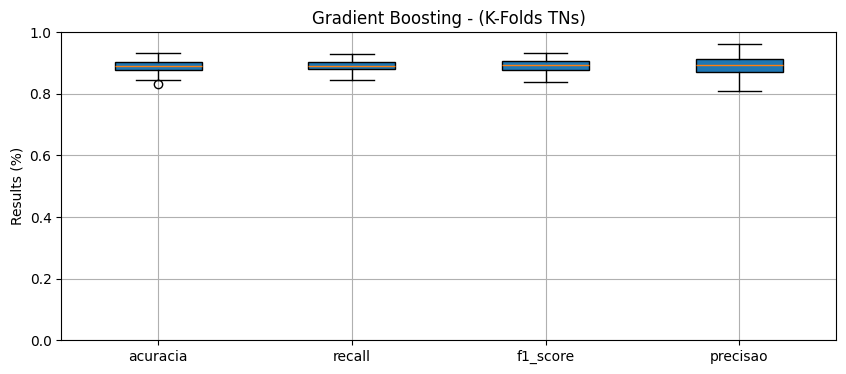

In [75]:
plt.figure(figsize=(10, 4))
plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)
plt.grid(True)
plt.ylim(0.0, 1.0)
plt.title('Gradient Boosting - (K-Folds TNs)')
plt.ylabel('Results (%)')
# plt.savefig('images/boxplot.png', bbox_inches='tight', dpi = 300)
plt.show()

### Criaçao do modelo ( RANDOM FOREST )

In [76]:
tn_create_model = tn_base.sample(n=len(fn_base), random_state=42)
tn_create_model = tn_create_model.drop_duplicates(ignore_index=True)

# contat
base_final = pd.concat([fn_base, tn_create_model])

# resetando o index da base final
base_final = base_final.reset_index(drop=True)

# labels
y = base_final['y_true']
X = base_final.drop(['y_true'], axis=1)

## 6.1) Realização da divisão da base para treino e teste - (30% para treino 70% para teste)
"""
aqui é realizada a divisão da base para treino e teste

estabelecendo o critério de divisão 30-70

30% da base sendo utilizada para teste  
70% da base sendo utilizada para treinamento 

"""

# separação treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state = 42)

def tabela_divisao(y_train, y_test):
    treino = pd.DataFrame(y_train.value_counts()).rename({'count': 'Treinamento'}, axis=1).rename_axis(None, axis=0)
    teste = pd.DataFrame(y_test.value_counts()).rename({'count': 'Teste'}, axis=1).rename_axis(None, axis=0)
    df_dist = pd.concat([treino, teste], axis=1)
    df_dist['Total'] = df_dist.sum(axis=1)
    pd.concat([df_dist, df_dist.sum().to_frame('Total').T]).T
    return df_dist.T

tabela_divisao(y_train, y_test)

y_predictions = {}

#### 6.2) Realização do treino e teste dos modelos utilizando os modelos presentes no artigo.

aqui é realizado o carregamento dos algoritmos de classificação e iniciado o processo de treinamento e teste dos modelos

#### Support Vector Machine

In [77]:
from sklearn.svm import SVC

clf = SVC(gamma='auto', random_state=42)
clf.fit(X_train, y_train)

SVC(gamma='auto', random_state=42)

In [78]:
y_predictions['SVM'] = clf.predict(X_test)

In [79]:
accuracy_score(y_test, y_predictions['SVM'])

0.6196319018404908

#### Random Forest

In [80]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [81]:
y_predictions['Random Forest'] = rf.predict(X_test)

In [82]:
accuracy_score(y_test, y_predictions['Random Forest'])

0.9141104294478528

In [83]:
from sklearn.pipeline import Pipeline
from joblib import dump

In [84]:
dump(vectorizer, 'vectorizer.joblib', compress=True)

['vectorizer.joblib']

In [85]:
dump(rf, 'rf_corretor.joblib', compress=True)

['rf_corretor.joblib']

##### 6.3) Explicabilidade random forest

In [86]:
import lime
import numpy as np
import lime.lime_tabular

In [87]:
predict_fn_rf = lambda x: rf.predict_proba(x).astype(float)
X = X_train.values
# explainer = lime.lime_tabular.LimeTabularExplainer(X,feature_names = X_train.columns, discretize_continuous=True)
explainer = lime.lime_tabular.LimeTabularExplainer(X,feature_names = X_train.columns)

In [88]:
X_test

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZV,ZW,ZX,ZY,ZZ,y_predecessor,y_sucessor,cg_p,cg_w,cg_s
463,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,12,3,12
203,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,1,12,12,1
253,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,12,13
162,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,12,12,12
290,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,12,12,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,12,12,1
499,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,1,1,12,1,13
186,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,12,12,13
222,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,12,12,12


In [89]:
choosen_instance = X_test.values[0]
exp = explainer.explain_instance(choosen_instance, predict_fn_rf,num_features=10)
exp.show_in_notebook(show_all=False)

c:\Users\kimli\Documents\GitHub\PIBIC\corretor\corretor_env\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [90]:
choosen_instance = X_test.values[4]
exp = explainer.explain_instance(choosen_instance, predict_fn_rf,num_features=10)
exp.show_in_notebook(show_all=False)

c:\Users\kimli\Documents\GitHub\PIBIC\corretor\corretor_env\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


#### Logistic Regression

In [91]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)

LogisticRegression(random_state=42)

In [92]:
y_predictions['Logistic Regression'] = model.predict(X_test)

In [93]:
accuracy_score(y_test, y_predictions['Logistic Regression'])

0.8404907975460123

#### Gradient Boosting

In [94]:
from sklearn.ensemble import GradientBoostingClassifier
gb = GradientBoostingClassifier(random_state=42)
gb.fit(X_train, y_train)

GradientBoostingClassifier(random_state=42)

In [95]:
y_predictions['Gradient Boosting'] = gb.predict(X_test)

In [96]:
accuracy_score(y_test, y_predictions['Gradient Boosting'])

0.8773006134969326

## PASSO 7) Apresentação dos resultados

### 7.1) Confusion Matrix

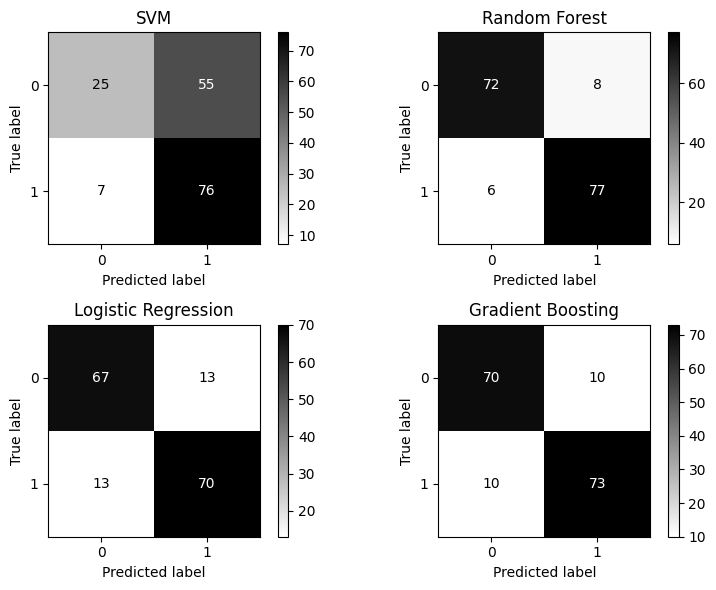

In [97]:
fig, axs = plt.subplots(2, 2, figsize=(8, 6))

for model_name, y_pred, ax in zip(y_predictions.keys(), y_predictions.values(), axs.flat):
    cm = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test, y_pred), display_labels=clf.classes_, )
    cm.plot(ax=ax, cmap='binary', values_format='d')
    ax.grid(False)
    ax.set_title(model_name)
plt.tight_layout()
# plt.savefig('imagens/matriz_confusao.png', bbox_inches='tight', dpi = 300)

In [98]:
dfs = {}
for model_name, y_pred in y_predictions.items():
    report = {}
    report['accuracy'] = accuracy_score(y_test, y_pred)
    report['precision'] = precision_score(y_test, y_pred)
    report['recall'] = recall_score(y_test, y_pred)
    report['f1-score'] = f1_score(y_test, y_pred)
    dfs[model_name] = pd.DataFrame(report, index=[model_name])

### 7.2) Metrics - ACCURACY, PRECISION, RECALL, F1-SCORE

In [99]:
concatenated_df = pd.concat(dfs.values())
concatenated_df

,accuracy,precision,recall,f1-score
SVM,0.619632,0.580153,0.915663,0.710280
Random Forest,0.914110,0.905882,0.927711,0.916667
Logistic Regression,0.840491,0.843373,0.843373,0.843373
Gradient Boosting,0.877301,0.879518,0.879518,0.879518


In [100]:
plt.style.use('bmh')

### 7.3) Comparação métricas dos algoritmos

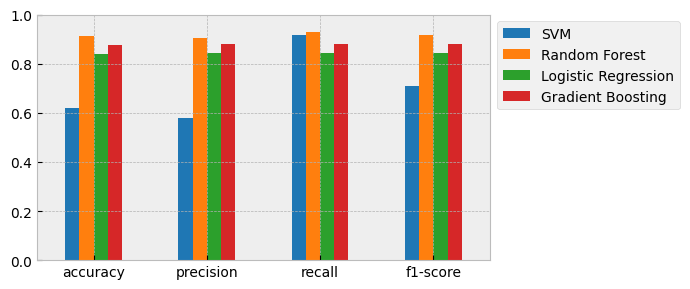

In [101]:
concatenated_df.T.plot.bar(figsize=(7, 3), ylim=(0, 1.0), color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'], grid=1).legend(bbox_to_anchor=(1, 1))
plt.xticks(rotation=0)
plt.tight_layout()

## PASSO 8) Realização da Validação cruzada

In [102]:
def validacao_cruzada(X_train, y_train, models):
    cv_results= {}
    scores = {}

    for model_name, model in models.items():
        score = cross_val_score(estimator=model, X=X_train, y=y_train, cv=10)
        media = score.mean()
        desvio = score.std()
        scores[model_name] = score
        cv_results[model_name] = {'Validação Cruzada': "%.5f" % media, 'Desvio Padrão': "%.5f" % desvio}
        
    return cv_results, scores

In [ ]:
cv_results, scores = validacao_cruzada(X_train, y_train,{
    'SVC': SVC(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Logistic Regression': LogisticRegression(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
})

#### comentários a cerca do boxplot


Observando o resultado da validação cruzada, podemos observar o comportamento do algoritmo quando o mesmo se depara com diferentes conjuntos de dados para o treinamento.

Destaque para o Random Forest que possuiu pouca variância se comparado com os outros modelos.

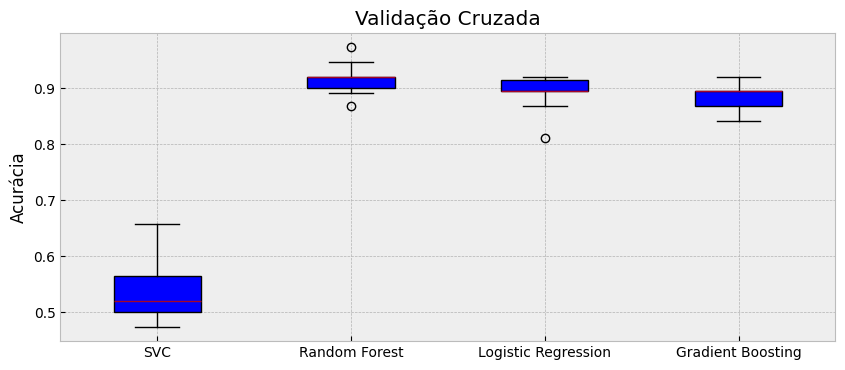

In [104]:
plt.figure(figsize=(10, 4))
plt.boxplot(scores.values(), tick_labels=scores.keys(), patch_artist=True)
plt.grid(True)
plt.title('Validação Cruzada')
plt.ylabel('Acurácia')
# plt.savefig('images/boxplot.png', bbox_inches='tight', dpi = 300)
plt.show()

### 8.1) Média e Desvio Padrão dos resultados obtidos na validação cruzada

está em ordem desc

In [105]:
scores

{'SVC': array([0.57894737, 0.5       , 0.5       , 0.57894737, 0.47368421,
        0.65789474, 0.52631579, 0.52631579, 0.47368421, 0.51351351]),
 'Random Forest': array([0.97368421, 0.92105263, 0.89473684, 0.92105263, 0.94736842,
        0.92105263, 0.92105263, 0.86842105, 0.92105263, 0.89189189]),
 'Logistic Regression': array([0.89473684, 0.89473684, 0.86842105, 0.92105263, 0.92105263,
        0.89473684, 0.89473684, 0.89473684, 0.92105263, 0.81081081]),
 'Gradient Boosting': array([0.89473684, 0.89473684, 0.89473684, 0.86842105, 0.89473684,
        0.89473684, 0.92105263, 0.84210526, 0.86842105, 0.86486486])}

####  Media ( validaçao cruzada )

In [106]:
np.mean(scores['Random Forest'])

np.float64(0.9181365576102417)

In [107]:
np.mean(scores['Logistic Regression'])

np.float64(0.8916073968705547)

In [108]:
np.mean(scores['Gradient Boosting'])

np.float64(0.883854907539118)

In [109]:
np.mean(scores['SVC'])

np.float64(0.5329302987197724)

#### Desvio Padrão ( validaçao cruzada )

In [110]:
np.std(scores['Random Forest'])

np.float64(0.027731789739249203)

In [111]:
np.std(scores['Logistic Regression'])

np.float64(0.031170061848767746)

In [112]:
np.std(scores['Gradient Boosting'])

np.float64(0.021344356290586793)

In [113]:
np.std(scores['SVC'])

np.float64(0.05431829737380865)

# Avaliação Modelo 1

In [114]:
import re
import string
import unicodedata
import pandas as pd
import spacy as scy
from joblib import load
from itertools import product
from unidecode import unidecode
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import CountVectorizer

In [115]:
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\kimli\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

### Como o modelo antigo se comporta com os mesmos dados?

In [116]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [117]:
rf_e2 = load('rf_exp2.joblib')

In [118]:
base_relato = pd.read_csv('base_para_teste_final.csv')

## Criando saída do modelo

In [119]:
######################################################################################################################################################
# Pré-Processamento dos relatos
######################################################################################################################################################
def preprocess(relato):
    def remove_stop_words(relato):
        # Remove stop words em português
        sw = stopwords.words('portuguese')
        sw = [unidecode(word).upper() for word in sw]
        return ' '.join([token for token in re.split("[, ]", relato) if len(token) > 2 and token not in sw])
    
    def clean_relato(relato):
        # Remoção de números e pontuação
        relato = re.sub(r'(<[^<>]*>)|(&NBSP;)|(&nbsp;)', " ", relato)
        relato = re.sub(r"[^\w\s]", " ", relato)
        relato = re.sub(r"[\d]", " ", relato)
        relato = remove_stop_words(relato)
        return relato
    
    relato = clean_relato(relato)
    return relato

def normalize_text(text):
    if pd.isna(text):
        return text
    text = unicodedata.normalize('NFKD', text)
    text = ''.join(c for c in text if not unicodedata.combining(c))
    return text.upper()

print("Iniciando pré-processamento...")
base_relato['relato'] = base_relato['relato'].apply(normalize_text)
base_relato['relato_tratado'] = base_relato['relato'].apply(preprocess)
print("Pré-processamento finalizado!")
######################################################################################################################################################
# Predição utilizando o modelo1
######################################################################################################################################################
def loadOutputList(df_bop : pd.DataFrame):
    rf_exp_2 = load('rf_exp2.joblib')

    output_list = []

    for text in df_bop['relato_tratado']:
        text = text.split()
        df = pd.DataFrame(text, columns=['palavra'])

        df['y_palavra'] = rf_exp_2.predict(df['palavra'].to_list())

        for _, row in df.iterrows():
            output_list.append({
                'palavra': row['palavra'],
                'y_palavra': int(row['y_palavra']),
            })
        output_list.append({
                'palavra': '#',
                'y_palavra': 2,
            })
    
    output_list.pop()

    return pd.DataFrame(output_list)
print("Carregando predição do modelo...")
output_list = loadOutputList(base_relato)
print("Base de dados de predição criada!")
######################################################################################################################################################

Iniciando pré-processamento...
Pré-processamento finalizado!
Carregando predição do modelo...
Base de dados de predição criada!


In [120]:
gab = pd.read_csv('gabarito_corretor.csv')

mapeamento das palavras contidas na lista de saida ( output_list ) que estão contidas na coluna 'palavra' do gabarito

In [121]:
gab['y_pred'] = gab['palavra'].map(dict(zip(output_list['palavra'], output_list['y_palavra'])))

In [122]:
gab = gab.dropna()

In [123]:
gab['y_pred'] = gab['y_pred'].astype(int)

## Avaliação do modelo 1 na base de dados de Boletins

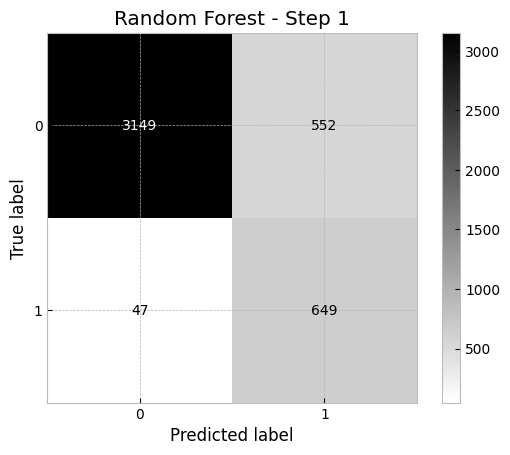

In [124]:
cm = confusion_matrix(gab['y'], gab['y_pred'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap='binary')
plt.title("Random Forest - Step 1")
plt.show()

In [125]:
fp = gab[(gab['y'] == 0) & (gab['y_pred'] == 1)]
fp.to_csv('falsos_positivos.csv', index=False,columns=['palavra'])
fp.shape

(552, 3)

In [126]:
accuracy = accuracy_score(gab['y'], gab['y_pred'])
accuracy

0.8637707527859905

In [127]:
precision = precision_score(gab['y'], gab['y_pred'])
precision

np.float64(0.5403830141548709)

In [128]:
recall = recall_score(gab['y'], gab['y_pred'])
recall

np.float64(0.9324712643678161)

In [129]:
f1 = f1_score(gab['y'], gab['y_pred'])
f1

np.float64(0.6842382709541381)

# Avaliação Modelo 2 ( corretor )

In [130]:
import re
import string
import unicodedata
import pandas as pd
import spacy as scy
from joblib import load
from itertools import product
from unidecode import unidecode
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import CountVectorizer

In [131]:
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\kimli\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

## Passo 1) Carregar o modelo1

O modelo1 inicial será utilizado para realização da predição dos tokens dos relatos. A saída desse modelo será utilizada para obtenção dos dados de entrada para o modelo2.

In [132]:
rf_e2 = load('rf_exp2.joblib')

## Passo 2) Carregar o modelo Corretor

In [133]:
rf_corretor = load('rf_corretor.joblib')

## Passo 3) Carregar os dados para predição

In [134]:
base_relato = pd.read_csv('base_para_teste_final.csv')

In [135]:
base_relato.shape

(231, 2)

## Passo 4) Criar lista de saída

### Passo 4.1) Pré-processamento dos relatos

Aqui são realizadas duas etapas a primeira o pré-processamento dos relatos, onde vamos adequar os relatos para ser a entrada do modelo1 removendo stopwors, caracteres especiais e etc...

### Passo 4.2) Realização da predição dos dados com o modelo1

A partir dos dados pré-processados, entramos na etapa de predição utilizando o modelo1.

Após a predição é retornado um dafaframe contendo os dados rotulados. Para cada relato é inserido um caracter coringa que será explicado logo a frente.

In [136]:
######################################################################################################################################################
# Pré-Processamento dos relatos
######################################################################################################################################################
def preprocess(relato):
    def remove_stop_words(relato):
        # Remove stop words em português
        sw = stopwords.words('portuguese')
        sw = [unidecode(word).upper() for word in sw]
        return ' '.join([token for token in re.split("[, ]", relato) if len(token) > 2 and token not in sw])
    
    def clean_relato(relato):
        # Remoção de números e pontuação
        relato = re.sub(r'(<[^<>]*>)|(&NBSP;)|(&nbsp;)', " ", relato)
        relato = re.sub(r"[^\w\s]", " ", relato)
        relato = re.sub(r"[\d]", " ", relato)
        relato = remove_stop_words(relato)
        return relato
    
    relato = clean_relato(relato)
    return relato

def normalize_text(text):
    if pd.isna(text):
        return text
    text = unicodedata.normalize('NFKD', text)
    text = ''.join(c for c in text if not unicodedata.combining(c))
    return text.upper()

print("Iniciando pré-processamento...")
base_relato['relato'] = base_relato['relato'].apply(normalize_text)
base_relato['relato_tratado'] = base_relato['relato'].apply(preprocess)
print("Pré-processamento finalizado!")
######################################################################################################################################################
# Predição utilizando o modelo1
######################################################################################################################################################
def loadOutputList(df_bop : pd.DataFrame):
    rf_exp_2 = load('rf_exp2.joblib')

    output_list = []

    for text in df_bop['relato_tratado']:
        text = text.split()
        df = pd.DataFrame(text, columns=['palavra'])

        df['y_palavra'] = rf_exp_2.predict(df['palavra'].to_list())

        for _, row in df.iterrows():
            output_list.append({
                'palavra': row['palavra'],
                'y_palavra': int(row['y_palavra']),
            })
        output_list.append({
                'palavra': '#',
                'y_palavra': 2,
            })
    
    output_list.pop()

    return pd.DataFrame(output_list)
print("Carregando predição do modelo...")
output_list = loadOutputList(base_relato)
print("Base de dados de predição criada!")
######################################################################################################################################################

Iniciando pré-processamento...
Pré-processamento finalizado!
Carregando predição do modelo...
Base de dados de predição criada!


essa é a estrutura gerada após a predição do modelo1

In [137]:
output_list

,palavra,y_palavra
0,VITIMA,0
1,RELATA,0
2,FEVEREIRO,0
3,VOLTA,0
4,MOCA,0
...,...,...
24337,PASSANDO,0
24338,HAVIA,1
24339,CAIDO,0
24340,GOLPE,0


### Estratégia utilizada para separação dos textos no dataframe abaixo:

É evidente que os relatos não estão dispostos em texto corrido.  

Qual o passo a passo?  

Passo 1) Pré-processamento: Aqui vamos remover stopwords, caracteres especiais e etc 
Logo, após isso vamos realizar a tokenização do relato, transformando o memso em uma vetor de tokens que será armazenada em um dataframe.  

Passo 2) Inserção do delimitador utilizando caracter coringa '#' : Após a inserção de cada vetor de tokens um caractere coringa será inserido ao final do processo de inserção. Este por sua vez tem o papel de delimitar o inicio e fim de um documento de texto tokenizado.

Após a criação da lista de saída (output_list) é realizada a validação da quantidade de '#', verificando se a mesma corresponde a quantidade de relatos na base

In [138]:
output_list[output_list['palavra'] == '#']

,palavra,y_palavra
116,#,2
318,#,2
548,#,2
623,#,2
897,#,2
...,...,...
23888,#,2
23958,#,2
24035,#,2
24130,#,2


## Passo 5) Criar lista temporária

- Para cada item, realizar a predição com o modelo do João
- Inserir a predição na lista de saída.
- Se a predição for negativa, inserir a predição na lista temporária, guardando o indice na lista de saída.

In [139]:
def vector_input_corretor(output_list : pd.DataFrame):
    
    def LoadPedSucWord(output_list : pd.DataFrame):
        list_aux_psw = []
        df_aux = output_list.copy()
        print(df_aux)

        df_aux['predecessor'] = df_aux['palavra'].shift(1).fillna('#')
        df_aux['y_predecessor'] = df_aux['predecessor'].apply(
            lambda x: df_aux[df_aux['palavra'] == x]['y_palavra'].iloc[0] if x != '#' else 2
        )

        df_aux['sucessor'] = df_aux['palavra'].shift(-1).fillna('#')
        df_aux['y_sucessor'] = df_aux['sucessor'].apply(
            lambda x: df_aux[df_aux['palavra'] == x]['y_palavra'].iloc[0] if x != '#' else 2
        )

        print(df_aux)

        for _, row in df_aux.iterrows():
            list_aux_psw.append({
                'predecessor': row['predecessor'],
                'y_predecessor': int(row['y_predecessor']),
                'palavra': row['palavra'],
                'y_palavra': int(row['y_palavra']),
                'sucessor': row['sucessor'],
                'y_sucessor': int(row['y_sucessor']),
            })

        return pd.DataFrame(df_aux)

    print("Realizando coleta de predecessores e sucessores...")
    temp_list = LoadPedSucWord(output_list)
    temp_list = temp_list[temp_list['y_palavra'] == 0].reset_index()
    indices_originais = temp_list['index']
    print("Predecessores e Sucessores coletados!")

    def bigrams_vector(lista_tokens):
        vectorizer = load('vectorizer.joblib')
        alfabeto = list(string.ascii_uppercase)
        alfabeto_bigrams = [''.join(bigram) for bigram in list(product(alfabeto, repeat=2))]
        vector = vectorizer.transform(lista_tokens)
        return pd.DataFrame(vector.todense(), columns=alfabeto_bigrams)

    print("Criando vetor de bigramas para os tokens...")
    token = temp_list['palavra']
    tokens_vector_bigrams = bigrams_vector(token.to_list())
    print("Vetores de bigramas dos tokens criados!")
    print("Concatenando vetor de bigramas com dados de predecessores e sucessores dos tokens...")
    tokens_vector_bigrams = pd.concat([tokens_vector_bigrams, temp_list[['predecessor','y_predecessor', 'palavra', 'y_palavra','sucessor', 'y_sucessor']]], axis=1)
    print("Concatenação concluída!")

    def create_base_cg(lista_tokens):
        nlp = scy.load('pt_core_news_lg')
        def renomear(doc):
            mapeamento_pos = {
                'NOUN': '<SUBSTANTIVO>',
                'PROPN': '<SUBSTANTIVO>',
                'VERB': '<VERBO>',
                'AUX': '<VERBO>',
                'ADJ': '<ADJETIVO>',
                'ADV': '<ADVERBIO>',
                'PUNCT': '<PONTUACAO>',
                'CCONJ': '<CONJUNCAO>',
                'SCONJ': '<CONJUNCAO>',
                'PRON': '<PRONOME>',
                'DET': '<ARTIGO>',
                'ADP': '<PREPOSIÇÃO>',
                'NUM': '<NUMERAL>',
                'SYM': '<SIMBOLO>',
                'X': '<PALAVRA ESTRANGEIRA>',
                'SPACE': '<ESPACO>',
            }
            
            return [mapeamento_pos.get(token.pos_, token.pos_) for token in doc]


        word_class = []
        for token in lista_tokens:
            if token == '#':
                word_class.append('<NULL>')
            else:
                lreview = token.lower()
                ldoc = nlp(lreview)
                classes = renomear(ldoc)
                for i in range(len(token.split())):
                    word_class.append(classes[i])

        return pd.DataFrame({'palavra':lista_tokens, 'classe':word_class})

    print("Realizando classificação gramatical dos predecessores, sucessores e dos tokens...")
    tokens_vector_bigrams['cg_p'] = create_base_cg(tokens_vector_bigrams['predecessor'])['classe']
    tokens_vector_bigrams['cg_w'] = create_base_cg(tokens_vector_bigrams['palavra'])['classe']
    tokens_vector_bigrams['cg_s'] = create_base_cg(tokens_vector_bigrams['sucessor'])['classe']
    print("Classificação gramatical realizada com sucesso!")
    def transformLabelsCG(tokens_vector_bigrams : pd.DataFrame):
        lb = LabelEncoder()

        labels = ['<SUBSTANTIVO>', '<VERBO>', '<ADJETIVO>', '<ADVERBIO>', '<PONTUACAO>',
                '<CONJUNCAO>', '<PRONOME>', '<ARTIGO>', '<PREPOSIÇÃO>', '<NUMERAL>',
                '<SIMBOLO>', '<PALAVRA ESTRANGEIRA>', '<ESPACO>', '<NULL>']

        lb.fit(labels)
        
        tokens_vector_bigrams['cg_p'] = lb.transform(tokens_vector_bigrams['cg_p'])
        tokens_vector_bigrams['cg_w'] = lb.transform(tokens_vector_bigrams['cg_w'])
        tokens_vector_bigrams['cg_s'] = lb.transform(tokens_vector_bigrams['cg_s'])

        return tokens_vector_bigrams
    print("Realizando a transformação dos labels da classificação gramatical para entrada adequada do modelo...")
    tokens_vector_bigrams = transformLabelsCG(tokens_vector_bigrams)
    print("Transformação dos labels da classificação gramatical realizada com sucesso!")
    print("Removendo as colunas contendo os tokens dos predecessores, sucessores e palavras...")
    final_tokens_vector_bigrams = tokens_vector_bigrams.drop(['sucessor', 'predecessor','palavra','y_palavra'], axis=1)
    print("Remoção realizada com sucesso!")
    print("Retornando vetor de entrada para o modelo.")

    return final_tokens_vector_bigrams, indices_originais

In [140]:
vector_input_temp_list, indices_originais = vector_input_corretor(output_list)

Realizando coleta de predecessores e sucessores...
         palavra  y_palavra
0         VITIMA          0
1         RELATA          0
2      FEVEREIRO          0
3          VOLTA          0
4           MOCA          0
...          ...        ...
24337   PASSANDO          0
24338      HAVIA          1
24339      CAIDO          0
24340      GOLPE          0
24341   REGISTRA          0

[24342 rows x 2 columns]
         palavra  y_palavra predecessor  y_predecessor   sucessor  y_sucessor
0         VITIMA          0           #              2     RELATA           0
1         RELATA          0      VITIMA              0  FEVEREIRO           0
2      FEVEREIRO          0      RELATA              0      VOLTA           0
3          VOLTA          0   FEVEREIRO              0       MOCA           0
4           MOCA          0       VOLTA              0  CONHECIDA           0
...          ...        ...         ...            ...        ...         ...
24337   PASSANDO          0      ALGUEM  

In [141]:
vector_input_temp_list

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZV,ZW,ZX,ZY,ZZ,y_predecessor,y_sucessor,cg_p,cg_w,cg_s
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,2,0,5,0,13
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,13,12
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,13,12,12
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,12,12,12
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,12,12,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18588,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,10,13
18589,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,10,13,13
18590,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,1,0,13,13,12
18591,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,13,12,13


In [142]:
vector_input_temp_list.dtypes

AA               int64
AB               int64
AC               int64
AD               int64
AE               int64
                 ...  
y_predecessor    int64
y_sucessor       int64
cg_p             int64
cg_w             int64
cg_s             int64
Length: 681, dtype: object

In [143]:
result = rf_corretor.predict(vector_input_temp_list)

In [144]:
temp_list = pd.DataFrame({'y_pred':result})

In [145]:
temp_list = pd.concat([temp_list, indices_originais], axis=1)

In [146]:
temp_list

,y_pred,index
0,0,0
1,0,1
2,0,2
3,0,3
4,0,4
...,...,...
18588,0,24336
18589,0,24337
18590,0,24339
18591,0,24340


## Passo 6) Iterar a lista temporária

- Para cada item, realizar a predição com o modelo corretor.
- Atualizar na lista de saída a predição, considerando a predição do modelo corretor e o índice que está armazenado na tupla.

In [147]:
select_index = output_list['y_palavra'][temp_list['index'].to_list()]
select_index

0        0
1        0
2        0
3        0
4        0
        ..
24336    0
24337    0
24339    0
24340    0
24341    0
Name: y_palavra, Length: 18593, dtype: int64

In [148]:
output_list['y_palavra'][38]

np.int64(0)

In [149]:
temp_list = temp_list.dropna(subset=['y_pred']).astype(int)

In [ ]:
for idx, pred_Ex2, pred_Corretor in zip(temp_list['index'].to_list(), select_index.to_list(), temp_list['y_pred'].to_list()):
    if int(pred_Corretor) == 1:
        output_list['y_palavra'][idx] = pred_Corretor
        palavra = output_list['palavra'][idx]
        print("palavra: ", palavra, "\n", "indice: ", idx, " -- ", "(M1: ", pred_Ex2, ") -- ", "(M2: ", pred_Corretor,')')
        print('-----------------------------------------------------')

In [151]:
output_list['y_palavra'][38]

np.int64(0)

## Passo 8) A lista de saída atualizada é o resultado final do modelo

In [152]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [153]:
gab = pd.read_csv('gabarito_corretor.csv')

realizando o processo de mapeamento das palavras contidas na lista de saída ( output_list ) que correspondem as palavras contidas no gabarito para realizaçao da avalizaçao

In [154]:
gab['y_pred'] = gab['palavra'].map(dict(zip(output_list['palavra'], output_list['y_palavra'])))

In [155]:
from nltk.corpus import stopwords

stopwords_list = stopwords.words('portuguese')
print("aquele" in stopwords_list)

True


In [156]:
gab[gab['palavra'] == 'DOS']

,palavra,y,y_pred


In [157]:
gab.dtypes

palavra     object
y            int64
y_pred     float64
dtype: object

In [158]:
gab.shape

(9148, 3)

A explicação da existencia de nulos é bem simples. Erros de digiação no momento da rotulação acabaram passando. Mas isso é bem simples de corrigir.

Destaque para o Penelope e Deyse, são nomes que estão contidos dentro de links, creio que o ideal seja a remoção dos mesmos por regex, pelo fato de que estes links, não são processados adequadamente removendo os nomes contidos neles na etapa de pre-processamento. Logo, os mesmos não vão constar no gabarito como nomes.

In [159]:
teste = gab[gab['y_pred'].isna()]
print(teste.shape)
teste

(4751, 3)


,palavra,y,y_pred
0,NILZA,1,NaN
1,LINDALCI,1,NaN
4,MONICA,1,NaN
5,ROVER,1,NaN
8,JUBER,1,NaN
...,...,...,...
9136,LACRADO,0,NaN
9139,INVADINDO,0,NaN
9143,GENTE,0,NaN
9145,EPA,0,NaN


In [160]:
gab = gab.dropna()
gab.shape

(4397, 3)

In [161]:
gab['y_pred'] = gab['y_pred'].astype(int)

### Etapa de avaliação do modelo 2

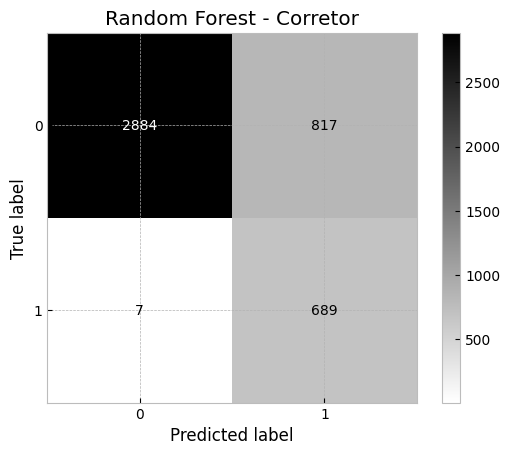

In [162]:
cm = confusion_matrix(gab['y'], gab['y_pred'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap='binary')
plt.title("Random Forest - Corretor")
plt.show()

## CAPTURANDO OS NOVOS Falsos Positivos DO MODELO 2

In [163]:
fp_m1 = pd.read_csv('M1_falsos_positivos.csv')
fp_m1

,palavra
0,PHONE
1,FAZER
2,VELOCIDADE
3,HELEENA
4,CHUVA
...,...
547,RENATAMATINIANO
548,GUAMA
549,ETC
550,SEUXIAOMI


In [164]:
fp_m2 = gab[(gab['y'] == 0) & (gab['y_pred'] == 1)]
fp_m2 = fp_m2.drop(columns=['y', 'y_pred'])
fp_m2

,palavra
1515,HUM
1525,DIVIDIR
1538,STALKING
1545,VIA
1554,AJUDARIA
...,...
9130,ELETRONICA
9137,ALTERARAO
9138,CENTO
9142,SEND


In [165]:
fp_m2_novos = fp_m2[~fp_m2['palavra'].isin(fp_m1['palavra'])]
fp_m2_novos.to_csv("M2_falsos_positivos.csv", index=False)

In [166]:
vector_input_temp_list

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZV,ZW,ZX,ZY,ZZ,y_predecessor,y_sucessor,cg_p,cg_w,cg_s
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,2,0,5,0,13
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,13,12
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,13,12,12
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,12,12,12
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,12,12,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18588,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,10,13
18589,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,10,13,13
18590,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,1,0,13,13,12
18591,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,13,12,13


In [167]:
def bigrams_vector(lista_tokens):
    vectorizer = load('vectorizer.joblib')
    alfabeto = list(string.ascii_uppercase)
    alfabeto_bigrams = [''.join(bigram) for bigram in list(product(alfabeto, repeat=2))]
    vector = vectorizer.transform(lista_tokens)
    return pd.DataFrame(vector.todense(), columns=alfabeto_bigrams)

print("Criando vetor de bigramas para os tokens...")
token = fp_m2_novos['palavra']
tokens_vector_bigrams = bigrams_vector(token.to_list())

Criando vetor de bigramas para os tokens...


In [168]:
alfabeto = list(string.ascii_uppercase)
alfabeto_bigrams = [''.join(bigram) for bigram in list(product(alfabeto, repeat=2))]
alfabeto_bigrams

['AA',
 'AB',
 'AC',
 'AD',
 'AE',
 'AF',
 'AG',
 'AH',
 'AI',
 'AJ',
 'AK',
 'AL',
 'AM',
 'AN',
 'AO',
 'AP',
 'AQ',
 'AR',
 'AS',
 'AT',
 'AU',
 'AV',
 'AW',
 'AX',
 'AY',
 'AZ',
 'BA',
 'BB',
 'BC',
 'BD',
 'BE',
 'BF',
 'BG',
 'BH',
 'BI',
 'BJ',
 'BK',
 'BL',
 'BM',
 'BN',
 'BO',
 'BP',
 'BQ',
 'BR',
 'BS',
 'BT',
 'BU',
 'BV',
 'BW',
 'BX',
 'BY',
 'BZ',
 'CA',
 'CB',
 'CC',
 'CD',
 'CE',
 'CF',
 'CG',
 'CH',
 'CI',
 'CJ',
 'CK',
 'CL',
 'CM',
 'CN',
 'CO',
 'CP',
 'CQ',
 'CR',
 'CS',
 'CT',
 'CU',
 'CV',
 'CW',
 'CX',
 'CY',
 'CZ',
 'DA',
 'DB',
 'DC',
 'DD',
 'DE',
 'DF',
 'DG',
 'DH',
 'DI',
 'DJ',
 'DK',
 'DL',
 'DM',
 'DN',
 'DO',
 'DP',
 'DQ',
 'DR',
 'DS',
 'DT',
 'DU',
 'DV',
 'DW',
 'DX',
 'DY',
 'DZ',
 'EA',
 'EB',
 'EC',
 'ED',
 'EE',
 'EF',
 'EG',
 'EH',
 'EI',
 'EJ',
 'EK',
 'EL',
 'EM',
 'EN',
 'EO',
 'EP',
 'EQ',
 'ER',
 'ES',
 'ET',
 'EU',
 'EV',
 'EW',
 'EX',
 'EY',
 'EZ',
 'FA',
 'FB',
 'FC',
 'FD',
 'FE',
 'FF',
 'FG',
 'FH',
 'FI',
 'FJ',
 'FK',
 'FL',
 'FM',

In [169]:
df_result = tokens_vector_bigrams.merge(vector_input_temp_list, on=alfabeto_bigrams, how='left')
df_result

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZV,ZW,ZX,ZY,ZZ,y_predecessor,y_sucessor,cg_p,cg_w,cg_s
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,12,13,13
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,13,12
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,12,12,12
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,13,12,13
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,12,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
887,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,6,6,6
888,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,6,6,6
889,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,6,6,6
890,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,6,6,6


In [170]:
df_result.drop_duplicates(subset=alfabeto_bigrams).shape

(265, 681)

Para verificar se se trata realmente dos 375 tokens ( falsos positivos novos )

In [171]:
df_result.drop_duplicates(subset=alfabeto_bigrams).shape

(265, 681)

#### Estes tokens possuem vizinhos que são nomes?

Dos 375 tokens - 109 possuem ambos os vizinhos nomes ( tanto predecessor quando sucessor )

In [172]:
pred_n_suce_n = df_result[(df_result['y_predecessor'] == 1) & (df_result['y_sucessor'] == 1)]
pred_n_suce_n.drop_duplicates(subset=alfabeto_bigrams)

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZV,ZW,ZX,ZY,ZZ,y_predecessor,y_sucessor,cg_p,cg_w,cg_s
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,13,12
27,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,0,12,0
31,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,13,12
33,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,1,0,12
47,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,0,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
857,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,13,13
872,0,0,0,1,0,0,1,0,0,0,...,0,0,0,0,0,1,1,13,12,12
882,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,12,12
885,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,0,12


Também entre estes tokens ( Os 375 ) 336 possuem ao menos um nome como vizinho

In [173]:
pred_nw_suce_nw = df_result[(df_result['y_predecessor'] == 1) | (df_result['y_sucessor'] == 1)]
pred_nw_suce_nw.drop_duplicates(subset=alfabeto_bigrams)

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZV,ZW,ZX,ZY,ZZ,y_predecessor,y_sucessor,cg_p,cg_w,cg_s
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,12,13,13
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,12,12,12
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,12,12
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,12,0,13
15,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,12,12,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
872,0,0,0,1,0,0,1,0,0,0,...,0,0,0,0,0,1,1,13,12,12
881,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,12,12,13
884,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,12,12,13
885,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,0,12


Os numeros não batem, né? se somar. O motivo é simples, um mesmo token pode estar em uma posiçao.

y_p = 0 | y_s = 0  
y_p = 1 | y_s = 0  
  
y_p = 0 | y_s = 1  
y_p = 1 | y_s = 1  

In [174]:
pred_w_suce_w = df_result[(df_result['y_predecessor'] == 0) & (df_result['y_sucessor'] == 0)]
pred_w_suce_w.drop_duplicates(subset=alfabeto_bigrams)

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZV,ZW,ZX,ZY,ZZ,y_predecessor,y_sucessor,cg_p,cg_w,cg_s
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,13,12,13
6,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,13,12,0
12,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,12,12,13
13,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,12,12,2
17,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,2,12,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
834,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,12
842,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,12,12,12
853,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,13,13,12
858,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,13,12,13


Um mesmo tokem pode possuir classificaçoes de predecessores e sucessores diferentes nas bases?

In [175]:
pred_nw_suce_nw = pred_nw_suce_nw.drop_duplicates(subset=alfabeto_bigrams)
pred_w_suce_w = pred_w_suce_w.drop_duplicates(subset=alfabeto_bigrams)

In [176]:
intecessao = pred_w_suce_w.merge(pred_nw_suce_nw, on=alfabeto_bigrams, how='inner')
intecessao

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,y_predecessor_x,y_sucessor_x,cg_p_x,cg_w_x,cg_s_x,y_predecessor_y,y_sucessor_y,cg_p_y,cg_w_y,cg_s_y
0,0,0,0,0,0,0,0,0,0,0,...,0,0,13,12,13,1,0,0,12,12
1,0,0,0,0,0,0,0,0,0,0,...,0,0,2,12,12,0,1,12,12,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,12,12,12,0,1,12,12,12
3,0,0,0,0,0,0,0,0,0,0,...,0,0,13,12,0,1,0,12,12,12
4,0,1,0,0,0,0,0,0,0,0,...,0,0,1,13,13,0,1,1,13,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,12,1,0,12,1,12
65,0,0,0,0,0,0,0,0,0,0,...,0,0,12,12,12,1,0,12,12,12
66,0,0,0,0,0,0,0,0,0,0,...,0,0,13,13,12,1,0,13,13,3
67,0,0,0,0,0,0,0,0,1,0,...,0,0,13,12,13,0,1,13,12,0


In [177]:
v = pred_w_suce_w.merge(pred_nw_suce_nw, on=alfabeto_bigrams, how='inner')

if not v.empty:
    print("Existe interseção entre os DataFrames.")
else:
    print("Não existe interseção entre os DataFrames.")


Existe interseção entre os DataFrames.


#### Explicabilidade dos Falsos Positivos

In [178]:
rf_corretor = load('rf_corretor.joblib')

In [179]:
importancia_features = rf_corretor.feature_importances_

feature_names = df_result.columns 
importancia_df = pd.DataFrame({
    'Feature': feature_names,
    'Importância': importancia_features
}).sort_values(by='Importância', ascending=False)

importancia_df


,Feature,Importância
676,y_predecessor,0.094741
679,cg_w,0.058158
678,cg_p,0.043889
677,y_sucessor,0.039415
338,NA,0.033844
...,...,...
189,HH,0.000000
190,HI,0.000000
191,HJ,0.000000
192,HK,0.000000


In [180]:
import lime
import numpy as np
import lime.lime_tabular

predict_fn_rf = lambda x: rf_corretor.predict_proba(x).astype(float)

X = df_result.values

explainer = lime.lime_tabular.LimeTabularExplainer(X, feature_names=df_result.columns)

choosen_instance = df_result.values[13]

exp = explainer.explain_instance(choosen_instance, predict_fn_rf, num_features=10)

exp.show_in_notebook(show_all=False)


c:\Users\kimli\Documents\GitHub\PIBIC\corretor\corretor_env\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


## Falsos negativos

In [181]:
fn = gab[(gab['y'] == 1) & (gab['y_pred'] == 0)]

In [182]:
fn

,palavra,y,y_pred
151,KONSTANTIN,1,0
501,ASTULIO,1,0
630,PRIETE,1,0
831,CHAVES,1,0
980,PASTRELLI,1,0
1255,SOLZINHA,1,0
1484,PARSIFAL,1,0


In [183]:
accuracy = accuracy_score(gab['y'], gab['y_pred'])
accuracy

0.8125994996588584

In [184]:
precision = precision_score(gab['y'], gab['y_pred'])
precision

np.float64(0.45750332005312083)

In [185]:
recall = recall_score(gab['y'], gab['y_pred'])
recall

np.float64(0.9899425287356322)

In [186]:
f1 = f1_score(gab['y'], gab['y_pred'])
f1

np.float64(0.6257947320617621)